# Function 4

<b> Description of the Sample Application:</b> Address the challenge of optimally placing products across warehouses for a business with high online sales, where accurate calculations are costly and only feasible biweekly. To speed up decision-making, an ML model approximates these results within hours. The model has four hyperparameters to tune, and its output reflects the difference from the expensive baseline. Because the system is dynamic and full of local optima, it requires careful tuning and robust validation to find reliable, near-optimal solutions. 

## Final Status (After Round 13)

| Item | Value |
|---|---|
| Best Observed output | **0.590944** at (0.414590, 0.368465, 0.395107, 0.413740) (Week 13) |
| Improvement over the previous confirmed best (Week 8, 0.576869) | 1.02x (+0.0141) |
| Improvement over the best of the initial 30 points (-4.025542) | +4.6164 (difference; baseline is negative) |
| Queries used | 13 consecutive Weekly submissions |
| Data points | 30 initial + 13 weekly = **43** |

**Dependent Files:** 
- `initial_inputs.npy`
- `initial_outputs.npy`
- `plotting_utils.py` <br><br>
**Libraries Used:** <br>
`numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`

## Change Log

| Date | Week | Changes Made |
|---|---|---|
| 22/07/2026 | Week 1 | 1. Initial Version with 10 Data Point |
| 22/07/2026 | Week 2 | 1. Added Change Log and Progress Log.<br>2. Added new data point. |
| 03/08/2026 | Week 3 | 1. Added Week 2 data and output point to the dataset.<br>2. Added Leave-One-Out Cross-Validation (LOO-CV) to validate the GP surrogate (predictive RMSE + 95% CI calibration).<br>3. Checked ARD length-scales of the chosen kernel to see which input dimensions the GP treats as most sensitive.<br>4. Re-selected kernel (RBF vs Matérn) using LOO-CV RMSE as the primary criterion.<br>5. Reduced UCB β from 2.0 to 1.5.<br>6. Extended the consolidated BO function bayesian_optimization_step() to also handle kernel comparison + LOO-CV. |
| 11/08/2026 | Week 4 | 1. Appended Week 3 input and output datapoints to the dataset (now 33 points) - this point returned Y = 2602.25, a dramatic outlier versus everything seen so far (previous range: -32.6 to -0.066). Flagged and analysed explicitly.<br>2. Re-ran LOO-CV on the 33-point dataset: RMSE jumps from 1 to 560; holding out the new point shows the GP cannot predict it from its neighbours at all — evidence of a sharp, narrow peak rather than a smooth hill.<br>3. Increased multi-start restarts (50 → 150), to focus on acquisition-function robustness. A sharp spike is easy for a local optimiser to miss without enough restarts.<br>4. Kept β = 1.5 (balanced) rather than jumping to heavy exploitation, since the outlier hasn't yet been confirmed as reproducible. |
| 18/08/2026 | Week 5 | 1. Appended Week 4 input and output datapoints to the dataset: a point only 0.041 away from the Week 3 outlier, yet back to an ordinary value. This disproves the "broad good basin" hypothesis - the spike is either an extremely narrow feature or a possible anomaly.<br>2. **Change in Strategy:** Added a compositional kernel (broad RBF + narrow RBF) as a third candidate, able to represent both a smooth background and a sharp localized spike simultaneously. <br>4. **β increased (1.5 to 2.0)** because local exploitation was just empirically shown not to pay off.<br>5. Kept multi-start at 150. |
| 25/08/2026 | Week 6 | 1. Amended Week 5 input and output data points.<br>2. **Directional trend analysis**: with three points at known distances from the spike (0 → 2602, 0.012 → 0.561, 0.041 → -0.550), the value now rises *monotonically* as distance to the spike shrinks. This is new evidence favouring a genuine (if extremely narrow) peak over an anomaly, since noise would not produce a consistent monotonic trend across three independent queries.<br>3. **Strategy change**: committed to a **trust-region local search**: acquisition optimisation restricted to a small box around the Week 3 point, rather than searching the full unit cube — plus a **novelty constraint** so the query can't simply re-confirm an already-known location.<br>4. **β reduced 2.0→1.0** (shift toward exploitation), justified by the monotonic trend now supporting the spike as real.<br>5. Kernel re-selected on 35 points: **Matern** now wins on LOO-CV RMSE (previously Composite/RBF traded off). |
| 01/09/2026 | Week 7 | 1. Amended Week 6 input and output data points. (Y=0.444, dist 0.015 from spike), a **4th point that fits the same monotonic trend**, strengthening confidence the peak is real rather than noise.<br>2. **Hyperparameters tightened further**: Trust-region radius reduced from 0.05 to **0.03**, novelty threshold reduced from 0.015 to **0.010**, β reduced from 1.0 to **0.8**.<br>3. Kernel comparison re-run on 36 points: RBF/Matern/Composite now nearly tied (all ≈440 RMSE). The extra kernel flexibility is providing **diminishing returns** as more nearby points reduce reliance on any single kernel's assumptions. |
| 08/09/2026 | Week 8 | 1. Appended Week 7 point (Y=0.541, dist 0.010). The trend **plateaus** (0.541 at dist 0.010 is *lower* than 0.561 at dist 0.0116) rather than climbing toward 2602.<br>2. **Strategy redefined**: Introducing a **shell-constrained probe**: acquisition search restricted to a tight ring around the Week 3 spike, no farther than 0.008 from it, but no closer than 0.003 to *any* already-observed point. This will guarantee a genuinely new test at a distance closer than anything tried in Weeks 4-7 (all ≥0.010).<br>3. Composite kernel's narrow component tightened further (length-scale bound lowered to 0.001-0.1) to allow representing an even sharper feature if one exists. |
| 23/09/2026 | Week 9 | 1. Added Week 8 point (Y=0.577, dist 0.003), best point so far, but the gain vs. Week 7 (dist 0.010, Y = 0.541) is marginal (+0.036) and **non-monotonic** relative to Week 5 (dist 0.0116, Y=0.561). This confirms this is a flat plateau.<br>2. Diminishing-returns analysis added.<br>3. Strategy Change: Abandoned further hyper-local refinement around the Week 3 spike. Switched to a **diversification search**, using UCB with a high exploration weight (β=2.5), explicitly excluding the already-saturated neighbourhood (within 0.15 of the spike), to find  second promising region rather than continuing to spend budget on a saturated area. |
| 30/09/2026 | Week 10 | 1. Added Week 9 result (Y=-20.576) - the diversification query landed in a substantially *worse* region than the local plateau, confirming the local neighbourhood around the spike remains the best-known area.<br>2. **Strategy reverted**: back to local exploitation, but now centred on the **best confirmed point** (Week 8, Y=0.577) rather than the unconfirmed spike itself - a deliberate distinction made explicit this week.<br>3. **Even tighter probe**: radius reduced to 0.008, novelty threshold to 0.0015 - the closest deliberate query yet. |
| 05/10/2026 | Week 11 | 1. Added Week 10 result (Y=0.5355, dist 0.0015 from spike) - **this is the closest probe yet, but it scored *lower* than Week 8 (dist 0.003, Y=0.577)**. Getting closer to the spike no longer increases Y at all; within this tiny neighbourhood the value simply fluctuates in the 0.44-0.58 band regardless of exact distance. Treated as decisive evidence the plateau is flat/noise-like at this scale, not a climbing ramp.<br>2. **Strategy change — stopped radial tightening, started clustering-informed exploration**: K-Means (k=4) applied to all 40 observed points confirms a single "hot" region (tight weekly probes + nearby initial points) has a far higher median Y than the rest of the space, validating continued focus on this neighbourhood. With tightening now shown to be unproductive, Week 11's query instead tests a **new angular direction** at the edge of the already-characterised shell (~0.04 from the spike) - inside the hot cluster's bounding region but outside the saturated inner 0.04 ball, to check whether the plateau is uniform in every direction or direction-dependent, which is new information rather than a near-duplicate of Weeks 4-10.<br>3. Only **1 query remains after this week** (Week 12 is final), so this query is chosen to maximise information gain for that last decision rather than simply re-confirming the plateau. |
| 14/10/2026 | Week 12 | 1. Added Week 11 result (Y=-0.5478 at d=0.0405 from the spike). It matches Week 4's -0.5499 at d=0.0407 almost exactly, even though the two points lie in different directions in x1 and x3. Both sit on the same side of the plateau in x2 and x4, which points to a **slope**, not noise.<br>2. **Strategy change: from global GP-UCB to a local trust-region step**: the global GP is dominated by the single 2602 spike (LOO-CV RMSE ~417 for every kernel, a statistical tie), so its suggestions are not stable between machines. Week 12 instead fits a **local linear surrogate** (ridge, spike excluded) to the 7 observations within 0.06 of the best confirmed point, validates it by LOO-CV (RMSE ~0.08 vs 0.57 for a flat plateau), and takes a **bounded uphill step** (radius 0.025) using a bootstrap-ensemble UCB. The search is fully seeded and closed-form, so it reproduces on any machine.<br>3. **PCA diagnostics added** (module theme): PCA of all 41 standardised inputs finds no useful compression (variance spread 37/30/20/13% across four components), while PCA of the local probes finds one dominant direction (76%) loaded on x2 and x4. The local regression independently finds the same two axes, but it is the regression, not PCA, that shows Y actually changes along them.<br>4. **Kernel tie-break rule added**: if LOO-CV RMSEs are within 1%, the kernel is chosen by a fixed priority (Matern, RBF, Composite) instead of by numerical noise.<br>5. Dashboard rebuilt with PCA scree, local sensitivity and ascent-direction panels. 1 query remains after this week (Week 13 is final). |
| 24/10/2026 | Week 13 (final) | 1. Added Week 12 result (Y=0.5340 at d=0.0248 from the best confirmed point). The local linear model had predicted about 1.32, so the **uphill step failed** (prediction error about 0.8). The result is slightly *below* the Week 8 plateau value (0.577).<br>2. **Diagnosis**: the straight-line model assumed Y keeps rising as x2 and x4 both fall. With 8 local points its LOO-CV RMSE is now 0.76 at the old setting (vs 0.54 for a flat plateau). The cause is curvature: Y has a peak in x2 near the Week 8 value, so moving x2 down (as the Week 12 step did) costs value, while moving x4 down still helps.<br>3. **Strategy change - local ARD Gaussian Process instead of a linear model**: a GP with one length-scale per input, fitted only to the 8 plateau points (spike excluded). Its LOO-CV RMSE is **0.033** (flat plateau 0.54, best ridge 0.36), and it predicts the held-out Week 4, 11 and 12 points to within about 0.02-0.03. Its fitted length-scales mark x1 and x3 as irrelevant (hit the upper bound) and x2 and x4 as the active inputs.<br>4. **REVISED final query**: the local-GP step is kept only as an exploit benchmark. The final query is an exploration probe for a second maximum (Matern-ARD GP on the 41 non-spike points, 0.05-0.12 from the best confirmed point, at least 0.05 from every queried point, mean + 2 x std).<br>5. Dashboard rebuilt: partial-dependence curves per input, a learning curve for the local model, and an exploration map (x1 vs x3) replacing the x2-x4 response map. |
| 31/10/2026 | Final | 1. Added the Week 13 result (input 0.414590-0.368465-0.395107-0.413740, Y=0.5909) as `X_w13_new_point` / `Y_w13_new_point`, appended in a guarded cell so re-running cannot duplicate it.<br>2. Checked the point equals the one the exploration rule produces, to 6 decimals (reproducibility check).<br>3. Compared forecast with outcome: predicted 0.364 +/- 0.386, observed 0.591. The probe is the **new best confirmed point**, above the Week 8 plateau (0.577).<br>4. Final dashboard rebuilt (forecast vs outcome for Weeks 12-13, full 13-week trajectory, result of every week by strategy phase, exploration map with the observed result, outputs against distance from the old best, top confirmed results).<br>5. Convergence trace extended to Week 13. |

## Progress Log

| Week | Query Submitted | Output Received | Best So Far (y) | Acquisition | β (beta) | Kernel | Strategy Notes |
|---|---|---|---|---|---|---|---|
|  |  |  |  |  |  |  |  |
| Week 1 | 0.383979-0.383515-0.340147-0.445246 | -0.06634074624810848 | -0.066341 | UCB | 2.5 | RBF | Exploration-heavy baseline, big jump over initial best |
| Week 2 | 0.441225-0.430034-0.274904-0.431415 | -1.0896527174598272 | -0.066341  | UCB | 2.0 | RBF vs Mater | Slightly reduced exploration, kernel comparison added |
| Week 3 | 0.382063-0.422612-0.423812-0.430108 | 0.5572213082937378 | 0.557221 | UCB | 1.5 | full space | RBF/Matern | Balanced strategy |
| Week 4 | 0.388813-0.456741-0.433948-0.448556 | -0.5498551985786473 *(d=0.041)* | 0.557221 | UCB | 1.5 | full space | RBF | Did not reproduce |
| Week 5 | 0.371052-0.422582-0.427366-0.430782 | 0.5609901334222198 *(d=0.012)* | 0.56099 | UCB | 2.0 | full space | RBF/Matern/Composite | Positive — trend emerging |
| Week 6 | 0.392081-0.417992-0.416776-0.437443 | 0.4439603735656701 *(d=0.015)* | 0.56099 | UCB | 1.0 | trust region r=0.05 | Matern | Trend confirmed |
| Week 7 | 0.386746-0.428888-0.425881-0.424238 | 0.5412633657393404 *(d=0.010)* | 0.56099 | UCB | 0.8 | trust region r=0.03 | Matern | Trend **plateaus** |
| Week 8 | 0.382401-0.420130-0.422214-0.429692 | 0.5768690397535008 *(d=0.003)* | 0.576869 | UCB | 0.8 | shell 0.003-0.008 | Matern | Closest probe confirms plateau, not a climb |
| Week 9 | 0.773956-0.438878-0.858598-0.697368 | -20.576083860513034 | 0.576869 | UCB | 2.5 | Global, excl. 0.15 around spike | Matern (LOO-CV, tied) | Diminishing returns confirmed. Pivot to diversification, searching for a second promising region |
| Week 10 | 0.382266-0.422660-0.424066-0.431595 | 0.5355018178716588 *(d=0.0015)* | 0.576869 | UCB | **0.5** | local, r=0.008, centred on **best confirmed point** (not spike) | Matern (LOO-CV) | Consolidating with 2 queries left; closest deliberate probe yet |
| Week 11 | 0.392451-0.453908-0.413167-0.451000 | -0.5478144020505584 *(d=0.0405)* | 0.576869 | UCB | 1.2 | cluster-bounded, outside 0.04 ball, new direction | Matern (LOO-CV, near-tie) | Result matches Week 4 (-0.550 at d=0.041): the plateau falls off on the +x2/+x4 side |
| Week 12 | 0.381161-0.402475-0.423449-0.412356 | 0.5339794849360797 *(d=0.0248)* | 0.576869 | Bootstrap-ensemble UCB | 1.0 | local linear model, trust region r=0.025 around best confirmed point | Ridge (spike excluded), LOO-CV selected | **Predicted 1.32, got 0.534**: slope assumption failed (x2 is peaked, not monotone) |
| Week 13 (final) | 0.414590-0.368465-0.395107-0.413740 | 0.5909440809549271 *(d=0.0685)* | 0.590944 | Mean + beta x std, exploration | 2.0 | **exploration probe for a second maximum, 0.05-0.12 from best confirmed point, >=0.05 from every queried point (spike excluded)** | Matern-ARD GP (own 41 non-spike points) | Forecast 0.364 +/- 0.386, observed **0.591**: the probe beat the Week 8 plateau (0.577) and became the new best confirmed point. |

In [235]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel, Matern
from scipy.optimize import minimize
from scipy.stats import norm

from plotting_utils import (plot_convergence, plot_parallel_coordinates)
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Load and Analyse the Data

In [238]:
# File Names
input_file  = "initial_inputs.npy"
output_file = "initial_outputs.npy"

# Load the Files
X0      = np.load(input_file)
Y0      = np.load(output_file)

In [240]:
# New data from the first submission (example inputs and outputs)
X_w1_new_point = np.array([0.383979, 0.383515, 0.340147, 0.445246]   , dtype=np.float64)    # from input.txt
Y_w1_new_point = np.array([-0.06634074624810848]                     , dtype=np.float64)    # from output.txt

# New data from Week 2 submission
X_w2_new_point = np.array([0.441225, 0.430034, 0.274904, 0.431415]     , dtype=np.float64)    # from input.txt
Y_w2_new_point = np.array([-1.0896527174598272]                        , dtype=np.float64)    # from output.txt

# New data from Week 3 submission
X_w3_new_point = np.array([0.382064, 0.422612, 0.423813, 0.430108]     , dtype=np.float64)   # from input.txt
Y_w3_new_point = np.array([2602.2537934860957]                         , dtype=np.float64)   # from output.txt

# New data from Week 4 submission
X_w4_new_point = np.array([0.388813, 0.456742, 0.433948, 0.448556]     , dtype=np.float64)  # from input.txt
Y_w4_new_point = np.array([-0.5498551985786473]                        , dtype=np.float64)  # from output.txt

# New data from Week 5 submission
X_w5_new_point = np.array([0.371066, 0.422591, 0.427371, 0.43079]      , dtype=np.float64)  # from input.txt
Y_w5_new_point = np.array([0.5609901334222198]                         , dtype=np.float64)  # from output.txt

# New data from Week 6 submission
X_w6_new_point = np.array([0.392081, 0.417992, 0.416776, 0.437443]     , dtype=np.float64)  # from input.txt
Y_w6_new_point = np.array([0.4439603735656701]                         , dtype=np.float64)  # from output.txt

# New data from Week 7 submission
X_w7_new_point = np.array([0.386746, 0.428888, 0.425881, 0.424238]     , dtype=np.float64)  # from input.txt
Y_w7_new_point = np.array([0.5412633657393404]                         , dtype=np.float64)  # from output.txt

# New data from Week 8 submission
X_w8_new_point = np.array([0.382401, 0.42013, 0.422214, 0.429692]      , dtype=np.float64)  # from input.txt
Y_w8_new_point = np.array([0.5768690397535008]                         , dtype=np.float64)  # from output.txt

# New data from Week 9 submission
X_w9_new_point = np.array([0.773956, 0.438878, 0.858598, 0.697368]     , dtype=np.float64)  # from input.txt
Y_w9_new_point = np.array([-20.576083860513034]                        , dtype=np.float64)  # from output.txt

# New data from Week 10 submission
X_w10_new_point = np.array([0.382266, 0.42266 , 0.424066, 0.431595]     , dtype=np.float64)  # from input.txt
Y_w10_new_point = np.array([0.5355018178716588]                         , dtype=np.float64)  # from output.txt

# New data from Week 11 submission
X_w11_new_point = np.array([0.392451, 0.453908, 0.413167, 0.451]     , dtype=np.float64)     # from input.txt
Y_w11_new_point = np.array([-0.5478144020505584]                     , dtype=np.float64)     # from output.txt

# New data from Week 12 submission
X_w12_new_point = np.array([0.381161, 0.402475, 0.423449, 0.412356]    , dtype=np.float64)  # from input.txt
Y_w12_new_point = np.array([0.5339794849360797]                        , dtype=np.float64)  # from output.txt

# New data from Week 13 submission
X_w13_new_point = np.array([0.41459, 0.368465, 0.395107, 0.41374]       , dtype=np.float64)  # from input.txt
Y_w13_new_point = np.array([0.5909440809549271]                         , dtype=np.float64)  # from output.txt

In [242]:
# Append the new data points
X_updated      = np.vstack((X0, X_w1_new_point
                             , X_w2_new_point
                             , X_w3_new_point
                             , X_w4_new_point
                             , X_w5_new_point
                             , X_w6_new_point
                             , X_w7_new_point
                             , X_w8_new_point
                             , X_w9_new_point
                             , X_w10_new_point
                             , X_w11_new_point
                             , X_w12_new_point
                             , X_w13_new_point
                           ))
Y_updated      = np.append(Y0, [Y_w1_new_point
                            , Y_w2_new_point
                            , Y_w3_new_point
                            , Y_w4_new_point
                            , Y_w5_new_point
                            , Y_w6_new_point
                            , Y_w7_new_point
                            , Y_w8_new_point
                            , Y_w9_new_point
                            , Y_w10_new_point
                            , Y_w11_new_point
                            , Y_w12_new_point
                            , Y_w13_new_point
                              ])

In [244]:
print(X_updated)
print(Y_updated)

# Save the updated arrays
np.save(r"initial_inputs.npy", X_updated)
np.save(r"initial_outputs.npy", Y_updated)

[[0.89698105 0.72562797 0.17540431 0.70169437]
 [0.8893564  0.49958786 0.53926886 0.50878344]
 [0.25094624 0.03369313 0.14538002 0.49493242]
 [0.34696206 0.0062504  0.76056361 0.61302356]
 [0.12487118 0.12977019 0.38440048 0.2870761 ]
 [0.80130271 0.50023109 0.70664456 0.19510284]
 [0.24770826 0.06044543 0.04218635 0.44132425]
 [0.74670224 0.7570915  0.36935306 0.20656628]
 [0.40066503 0.07257425 0.88676825 0.24384229]
 [0.6260706  0.58675126 0.43880578 0.77885769]
 [0.95713529 0.59764438 0.76611385 0.77620991]
 [0.73281243 0.14524998 0.47681272 0.13336573]
 [0.65511548 0.07239183 0.68715175 0.08151656]
 [0.21973443 0.83203134 0.48286416 0.08256923]
 [0.48859419 0.2119651  0.93917791 0.37619173]
 [0.16713049 0.87655456 0.21723954 0.95980098]
 [0.21691119 0.16608583 0.24137226 0.77006248]
 [0.38748784 0.80453226 0.75179548 0.72382744]
 [0.98562189 0.66693268 0.15678328 0.8565348 ]
 [0.03782483 0.66485335 0.16198218 0.25392378]
 [0.68348638 0.9027701  0.33541983 0.99948256]
 [0.17034731 

In [246]:
# Assign X = X_updated and Y = Y_updated
X          = X_updated
Y          = Y_updated

# Analyse the Input Data
print("Input  Shape:", X.shape)
print("Inputs:\n", X)
print()

# Analyse the Output Data
print("Output Shape:", Y.shape)
print("Outputs:\n", Y)
print()

print(f"y Range: [: {Y.min()}, {Y.max()}]")
best_idx   = np.argmax(Y)
print(f"Best point: x = {X[best_idx]}, Y = {Y[best_idx]}")
print()

# Converting the Input and Output into a DataFram
df         = pd.DataFrame(X, columns = [f'X_{i+1}' for i in range(X.shape[1])])
df['Y'] = Y
print("Data Frame:\n", df)


Input  Shape: (43, 4)
Inputs:
 [[0.89698105 0.72562797 0.17540431 0.70169437]
 [0.8893564  0.49958786 0.53926886 0.50878344]
 [0.25094624 0.03369313 0.14538002 0.49493242]
 [0.34696206 0.0062504  0.76056361 0.61302356]
 [0.12487118 0.12977019 0.38440048 0.2870761 ]
 [0.80130271 0.50023109 0.70664456 0.19510284]
 [0.24770826 0.06044543 0.04218635 0.44132425]
 [0.74670224 0.7570915  0.36935306 0.20656628]
 [0.40066503 0.07257425 0.88676825 0.24384229]
 [0.6260706  0.58675126 0.43880578 0.77885769]
 [0.95713529 0.59764438 0.76611385 0.77620991]
 [0.73281243 0.14524998 0.47681272 0.13336573]
 [0.65511548 0.07239183 0.68715175 0.08151656]
 [0.21973443 0.83203134 0.48286416 0.08256923]
 [0.48859419 0.2119651  0.93917791 0.37619173]
 [0.16713049 0.87655456 0.21723954 0.95980098]
 [0.21691119 0.16608583 0.24137226 0.77006248]
 [0.38748784 0.80453226 0.75179548 0.72382744]
 [0.98562189 0.66693268 0.15678328 0.8565348 ]
 [0.03782483 0.66485335 0.16198218 0.25392378]
 [0.68348638 0.9027701  0.335

# Data Exploration

In [26]:
# Basic Staistics
print("Display Basic Statistics for the Dataset\n",df.describe())

Display Basic Statistics for the Dataset
              X_1        X_2        X_3        X_4            Y
count  43.000000  43.000000  43.000000  43.000000    43.000000
mean    0.506023   0.460064   0.456982   0.467592    48.047673
std     0.257292   0.258364   0.229363   0.246421   398.905520
min     0.037825   0.006250   0.042186   0.081517   -32.625660
25%     0.359014   0.375990   0.305970   0.270500   -18.629778
50%     0.392451   0.438878   0.424066   0.437443   -13.122782
75%     0.735713   0.631249   0.613210   0.655196    -0.819754
max     0.985622   0.919592   0.939178   0.999483  2602.253793


In [28]:
# Check for Missing Values in the Data Set
print("Missing Values in the Dataset\n",df.isnull().sum())

Missing Values in the Dataset
 X_1    0
X_2    0
X_3    0
X_4    0
Y      0
dtype: int64


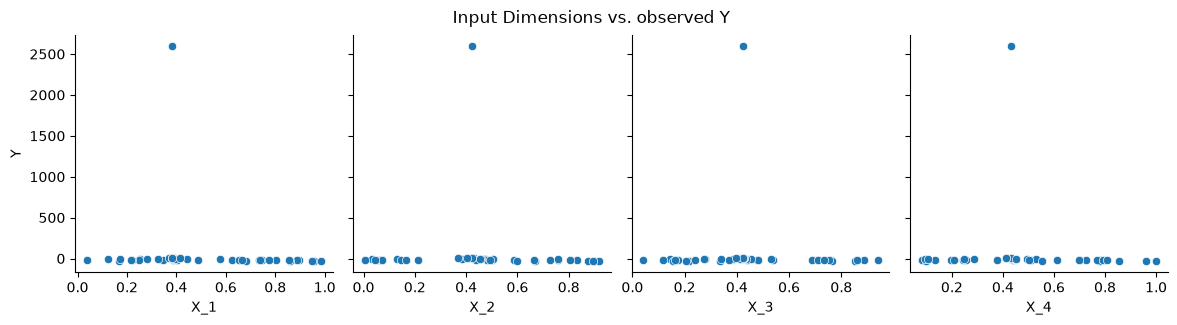

In [30]:
# Pairwise Scatter Plot, showing relationship of y for each input
sns.pairplot(df, y_vars = ['Y'], x_vars = ['X_1', 'X_2', 'X_3', 'X_4'], height = 3)
plt.suptitle("Input Dimensions vs. observed Y", y = 1.05)
plt.show()

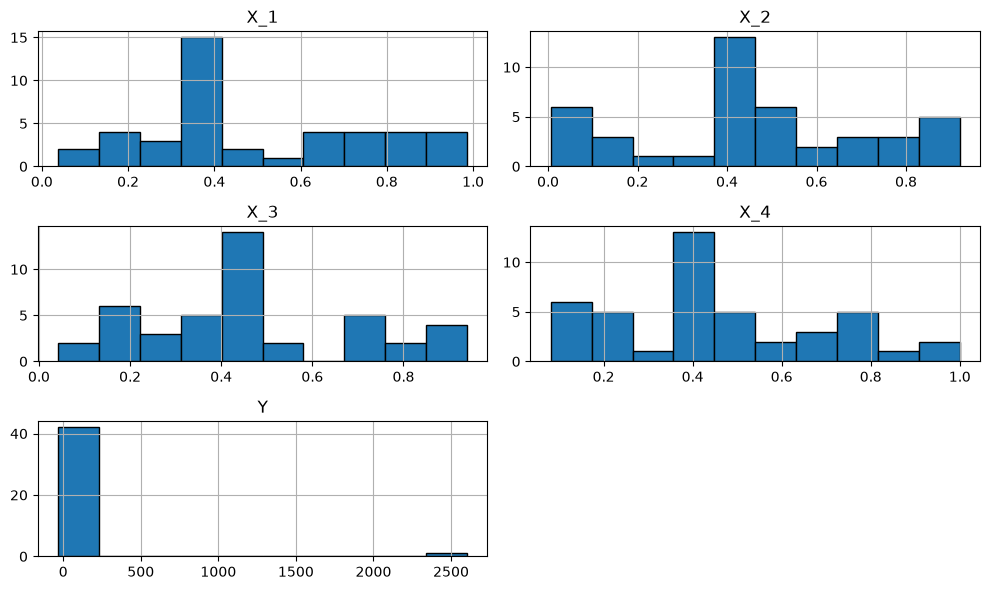

In [32]:
# Plot Histogram Visualisation for the columns of the DataFrame
df.hist(figsize = (10, 6), bins = 10, edgecolor = 'k' )
plt.tight_layout()
plt.show()

In [34]:
# Understanding Correlation between each input with y
labels      = ["X_1", "X_2", "X_3", "X_4"]
print("Correlation of each input with y:\n")

for i, lab in enumerate(labels):
    corr = np.corrcoef(X[:, i], Y)[0, 1]
    print(f" corr({lab}, Y) = {corr}")

Correlation of each input with y:

 corr(X_1, Y) = -0.0882096364174773
 corr(X_2, Y) = -0.031647606936502974
 corr(X_3, Y) = -0.026953482835193315
 corr(X_4, Y) = -0.033411685243507384


<Axes: >

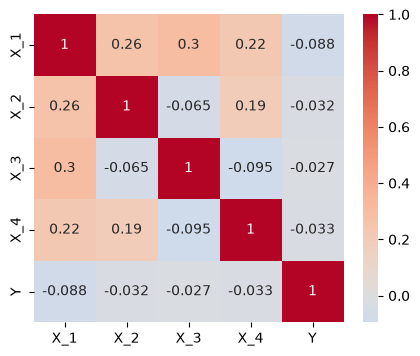

In [36]:
# Plotting the Correlation heatmap
plt.figure(figsize = (5, 4))
sns.heatmap(df.corr(), annot = True, cmap = "coolwarm", center = 0)

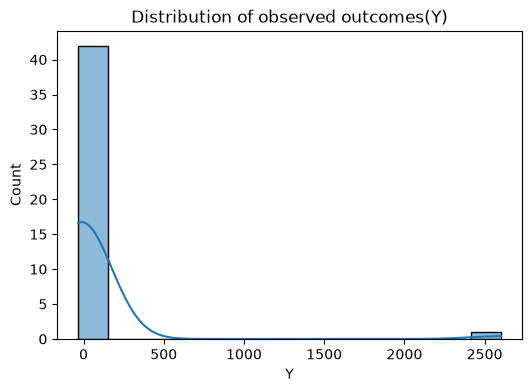

In [38]:
# Plot the Histogram for y to check for Outliers
plt.figure(figsize = (6,4))
sns.histplot(df['Y'], kde = True)
plt.title("Distribution of observed outcomes(Y)")
plt.show()

# Initialize Gaussian Process

In [41]:
#Define the kernel and initialise the GP model

kernel_rbf = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.3, 0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 2.0)) \
                + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))
gpr   = GaussianProcessRegressor(kernel = kernel_rbf, normalize_y = True, n_restarts_optimizer = 10, random_state = 0 )

# Fit the Gaussian Processes to existing data

In [44]:
# Train the model

gpr.fit(X, Y)
print("Learned kernel: ", gpr.kernel_)

Learned kernel:  9.72**2 * RBF(length_scale=[0.01, 0.01, 0.01, 0.01]) + WhiteKernel(noise_level=0.1)


# Compute the UCB acquisition function

- UCB(x)=μ(x)+β⋅σ(x)
- A high beta favors exploration (uncertainty) over exploitation (predicted mean).
- Week 1 uses beta = 2.5, reflecting the 90:10 exploration-heavy strategy.

In [48]:
n_candidates = 50000
candidates   = np.random.uniform(0, 1, size = (n_candidates, 4))

mu, std      = gpr.predict(candidates, return_std = True)

# Setting a higher beta(= 2.5) for Week -1
beta         = 2.5
ucb          = mu + beta * std

best_ucb_idx   = np.argmax(ucb)
next_point     = candidates[best_ucb_idx]

print(f"Suggested next Query Point: {next_point}")
print(f"Predicted Mean(μ): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (σ): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Suggested next Query Point: [0.36216303 0.42499588 0.41194661 0.39181434]
Predicted Mean(μ): 4.888131e+01
Predicted Std (σ): 3.833033e+03
UCB Score: 9.631463e+03


# Week 2: Evaluating Kernel - RBF vs. Matern

In [51]:
Y_mean, Y_std  = Y.mean(), Y.std()
Y_norm         = (Y - Y_mean) / Y_std

kernel_rbf     = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.3, 0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 2.0)) \
                    + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))

kernel_matern  = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale = [0.3, 0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 2.0), nu = 2.5) \
                    + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))

gpr_rbf        = GaussianProcessRegressor(kernel = kernel_rbf, n_restarts_optimizer = 10, random_state = 0)
gpr_rbf.fit(X, Y_norm)

gpr_matern     = GaussianProcessRegressor(kernel = kernel_matern, n_restarts_optimizer = 10, random_state = 0)
gpr_matern.fit(X, Y_norm)

print("Learned kernel ( RBF)  :", gpr_rbf.kernel_)
print("Log-marginal-likelihood:", gpr_rbf.log_marginal_likelihood_value_)
print()
print("Learned kernel (Matern):", gpr_matern.kernel_)
print("Log-marginal-likelihood:", gpr_matern.log_marginal_likelihood_value_)

if gpr_rbf.log_marginal_likelihood_value_ >= gpr_matern.log_marginal_likelihood_value_:
    chosen_kernel, chosen_name = kernel_rbf, "RBF"
else:
    chosen_kernel, chosen_name = kernel_matern, "Matern (nu = 2.5)"

print()
print(f"Chosen kernel for Week 2: {chosen_name}")


Learned kernel ( RBF)  : 9.72**2 * RBF(length_scale=[0.01, 0.01, 0.01, 0.01]) + WhiteKernel(noise_level=0.1)
Log-marginal-likelihood: -159.66275775137882

Learned kernel (Matern): 5.81**2 * Matern(length_scale=[0.01, 0.01, 0.01, 0.01], nu=2.5) + WhiteKernel(noise_level=0.1)
Log-marginal-likelihood: -138.5866187532611

Chosen kernel for Week 2: Matern (nu = 2.5)


# Week 2: Bayesian Optimisation Function

In [54]:
def upper_confidence_bound(mu, sigma, beta = 2.0):
    """UCB(x) = mean + beta * std. Higher beta favours exploration."""
    return mu + beta * sigma


def expected_improvement(mu, sigma, Y_best, xi = 0.01):
    """EI(x) = E[max(f(x) - f(x_best), 0)]. More conservative than UCB."""
    with np.errstate(divide = 'warn'):
        improvement = mu - Y_best - xi
        Z    = improvement / sigma
        ei   = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


def suggest_next_point(X, Y, kernel, beta = 2.0, acquisition = 'ucb',
                        n_restarts_optimizer = 10, n_multistart = 50, seed = 42):
    
    Y_mean, Y_std = Y.mean(), Y.std()
    Y_norm        = (Y - Y_mean) / Y_std

    gp            = GaussianProcessRegressor(kernel = kernel, n_restarts_optimizer = n_restarts_optimizer, random_state = seed)
    gp.fit(X, Y_norm)

    n_dims        = X.shape[1]

    def neg_acq(x):
        x = np.atleast_2d(x)
        mu, sigma = gp.predict(x, return_std = True)
        mu        = mu * Y_std + Y_mean
        sigma     = sigma * Y_std
        if acquisition == 'ei':
            val   = expected_improvement(mu, sigma, Y.max())
        else:
            val   = upper_confidence_bound(mu, sigma, beta = beta)
        return -val[0]

    rng              = np.random.default_rng(seed)
    
    best_x, best_val = None, np.inf
    
    for _ in range(n_multistart):
        x0 = rng.uniform(0, 1, size=n_dims)
        res = minimize(neg_acq, x0, bounds = [(0, 1)] * n_dims, method = 'L-BFGS-B')
        if res.fun < best_val:
            best_val, best_x = res.fun, res.x

    mu_next, sigma_next = gp.predict(best_x.reshape(1, -1), return_std = True)
    mu_next = mu_next * Y_std + Y_mean
    sigma_next = sigma_next * Y_std

    return {
        'gp': gp,
        'next_x': best_x,
        'acq_value': -best_val,
        'mu': mu_next[0],
        'sigma': sigma_next[0],
    }


# Week 2: Query Selection

In [57]:
result = suggest_next_point(X, Y, chosen_kernel, beta = 2.0, acquisition = 'ucb')

next_x = result['next_x']

print(f"Kernel used            : {chosen_name}")
print(f"Suggested next point   : {next_x}")
print(f"Predicted mean (mu)    : {result['mu']:.6f}")
print(f"Predicted std (sigma)  : {result['sigma']:.6f}")
print(f"UCB score              : {result['acq_value']:.6f}")


Kernel used            : Matern (nu = 2.5)
Suggested next point   : [1. 1. 0. 1.]
Predicted mean (mu)    : 48.047673
Predicted std (sigma)  : 2293.696377
UCB score              : 4635.440427


# Week 2: Portal Submission 

In [60]:
# Format as required by the capstone portal: x1-x2 (6 decimal places)
submission_str = f"{next_x[0]:.6f}-{next_x[1]:.6f}-{next_x[2]:.6f}-{next_x[3]:.6f}"
print("Points to be submitted(Week 1):", submission_str)
print()

Points to be submitted(Week 1): 1.000000-1.000000-0.000000-1.000000



# Week 2: Visualise the Acquisition Function and Next Query Point

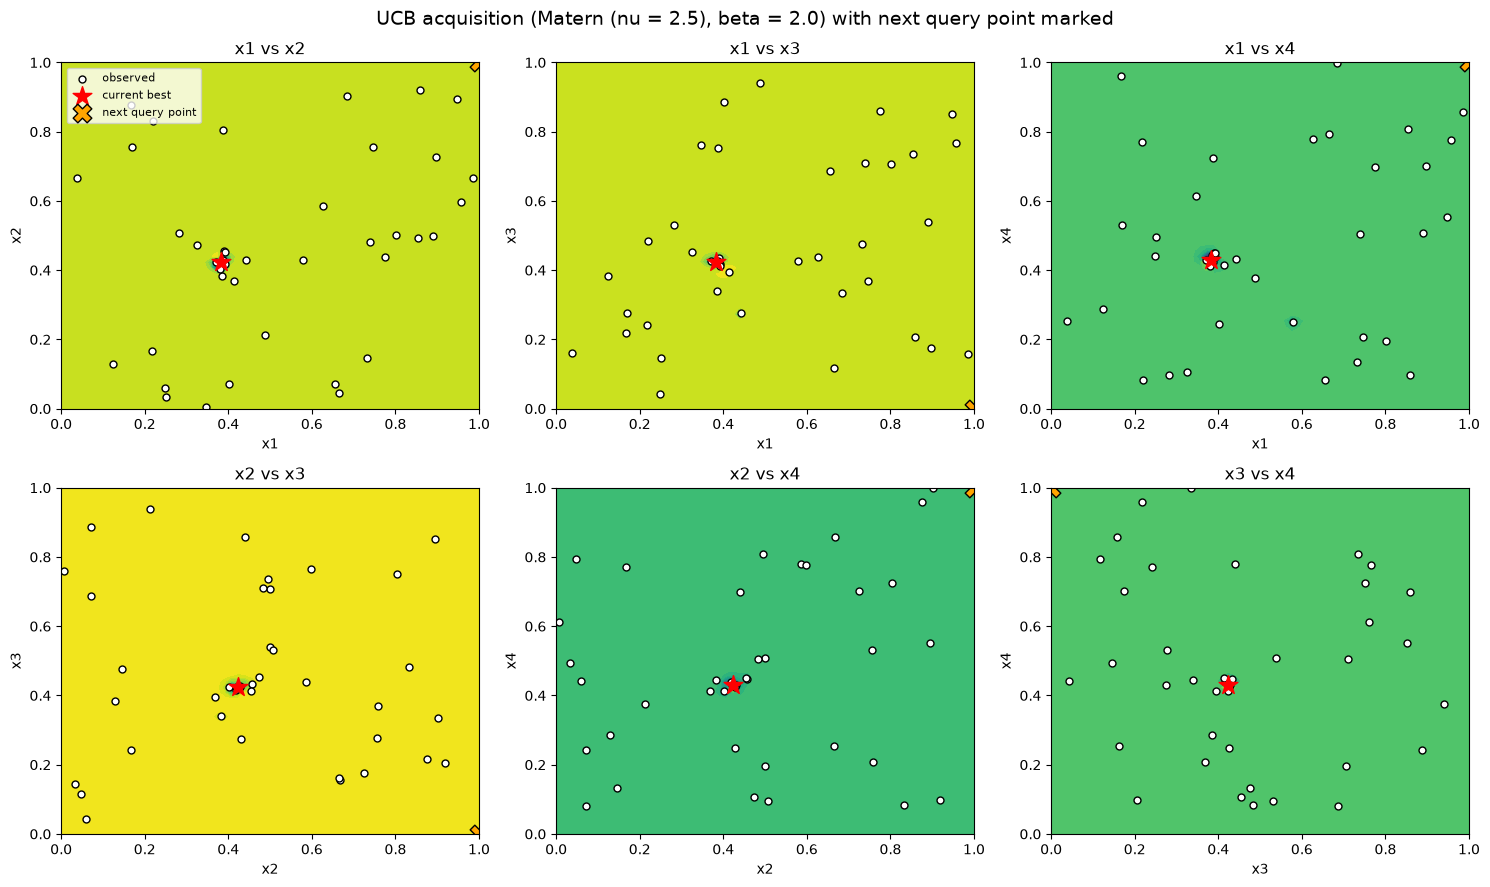

In [63]:
gp         = result['gp']
best_x_obs = X[np.argmax(Y)]

def ucb_full(x, beta = 2.0):
    x = np.atleast_2d(x)
    mu, sigma = gp.predict(x, return_std=True)
    return (mu * Y_std + Y_mean) + beta * (sigma * Y_std)

dim_pairs  = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
grid_n     = 60
grid       = np.linspace(0, 1, grid_n)

fig, axes  = plt.subplots(2, 3, figsize = (15, 9))
for ax, (i, j) in zip(axes.flat, dim_pairs):
    A, B   = np.meshgrid(grid, grid)
    pts    = np.tile(best_x_obs, (grid_n * grid_n, 1))
    pts[:, i] = A.ravel()
    pts[:, j] = B.ravel()
    Z = ucb_full(pts).reshape(grid_n, grid_n)
    ax.contourf(A, B, Z, levels = 25, cmap = 'viridis')
    ax.scatter(X[:, i], X[:, j], c = 'white', edgecolor = 'black', s = 25, label = 'observed')
    ax.scatter(best_x_obs[i], best_x_obs[j], c = 'red', marker = '*', s = 200, label = 'current best')
    ax.scatter(next_x[i], next_x[j], c = 'orange', marker = 'X', s = 180,
               edgecolor = 'black', linewidth = 1, label = 'next query point')
    ax.set_xlabel(f'x{i+1}')
    ax.set_ylabel(f'x{j+1}')
    ax.set_title(f'x{i+1} vs x{j+1}')
axes.flat[0].legend(fontsize = 8, loc = 'upper left')
fig.suptitle(f'UCB acquisition ({chosen_name}, beta = 2.0) with next query point marked', fontsize = 14)
plt.tight_layout()
plt.show()


# Week 3: Model Validation - Leave-One-Out Cross-Validation

In [66]:
kernel_rbf     = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(length_scale = [0.3, 0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 2.0)) \
                    + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))

kernel_matern  = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale = [0.3, 0.3, 0.3, 0.3], length_scale_bounds = (1e-2, 2.0), nu = 2.5) \
                    + WhiteKernel(noise_level = 1e-3, noise_level_bounds = (1e-6, 1e-1))

def loocv_gp(X, Y, kernel, n_restarts_optimizer = 5, seed = 0):

    n             = len(Y)
    preds_mu      = np.zeros(n)
    preds_sigma   = np.zeros(n)
    Y_mean, Y_std = Y.mean(), Y.std()

    for i in range(n):
        mask             = np.ones(n, dtype=bool)
        mask[i]          = False
        X_train, Y_train = X[mask], Y[mask]
        Y_train_norm     = (Y_train - Y_mean) / Y_std

        gp               = GaussianProcessRegressor(kernel = kernel, n_restarts_optimizer = n_restarts_optimizer, random_state = seed)
        gp.fit(X_train, Y_train_norm)

        mu, sigma        = gp.predict(X[i].reshape(1, -1), return_std = True)
        preds_mu[i]      = mu[0] * Y_std + Y_mean
        preds_sigma[i]   = sigma[0] * Y_std

    rmse                 = np.sqrt(np.mean((preds_mu - Y) ** 2))
    lower                = preds_mu - 1.96 * preds_sigma
    upper                = preds_mu + 1.96 * preds_sigma
    coverage             = np.mean((Y >= lower) & (Y <= upper))

    return {'rmse': rmse, 'coverage_95': coverage, 'preds_mu': preds_mu, 'preds_sigma': preds_sigma}


loocv_rbf                = loocv_gp(X, Y, kernel_rbf)
loocv_matern             = loocv_gp(X, Y, kernel_matern)

print(f"LOO-CV RBF    : RMSE = {loocv_rbf['rmse']   :.4f}   , 95% coverage = {loocv_rbf['coverage_95']   :.2f}")
print(f"LOO-CV Matern : RMSE = {loocv_matern['rmse']:.4f}   , 95% coverage = {loocv_matern['coverage_95']:.2f}")


LOO-CV RBF    : RMSE = 2383.5244   , 95% coverage = 0.86
LOO-CV Matern : RMSE = 1203.3009   , 95% coverage = 0.91


# Week: 3 Kernel Re-Selection

In [71]:
# Week 3: Kernel selection driven by LOO-CV RMSE

Y_mean, Y_std = Y.mean(), Y.std()
Y_norm        = (Y - Y_mean) / Y_std

gpr_rbf       = GaussianProcessRegressor(kernel = kernel_rbf, n_restarts_optimizer = 10, random_state = 0)
gpr_rbf.fit(X, Y_norm)

gpr_matern    = GaussianProcessRegressor(kernel = kernel_matern, n_restarts_optimizer = 10, random_state = 0)
gpr_matern.fit(X, Y_norm)

print("RBF    => LML:", gpr_rbf.log_marginal_likelihood_value_   , " learned kernel:", gpr_rbf.kernel_)
print("Matern => LML:", gpr_matern.log_marginal_likelihood_value_, " learned kernel:", gpr_matern.kernel_)

if loocv_rbf['rmse'] < loocv_matern['rmse']:
    chosen_kernel, chosen_name, chosen_gpr = kernel_rbf, "RBF", gpr_rbf
elif loocv_matern['rmse'] < loocv_rbf['rmse']:
    chosen_kernel, chosen_name, chosen_gpr = kernel_matern, "Matern (nu=2.5)", gpr_matern
else:
    # tie on LOO-CV RMSE -> fall back to LML
    if gpr_rbf.log_marginal_likelihood_value_ >= gpr_matern.log_marginal_likelihood_value_:
        chosen_kernel, chosen_name, chosen_gpr = kernel_rbf, "RBF", gpr_rbf
    else:
        chosen_kernel, chosen_name, chosen_gpr = kernel_matern, "Matern (nu=2.5)", gpr_matern

print(f"\nChosen kernel for Week 3: {chosen_name} (selected by LOO-CV RMSE)")


RBF    => LML: -159.66275775137882  learned kernel: 9.72**2 * RBF(length_scale=[0.01, 0.01, 0.01, 0.01]) + WhiteKernel(noise_level=0.1)
Matern => LML: -138.5866187532611  learned kernel: 5.81**2 * Matern(length_scale=[0.01, 0.01, 0.01, 0.01], nu=2.5) + WhiteKernel(noise_level=0.1)

Chosen kernel for Week 3: Matern (nu=2.5) (selected by LOO-CV RMSE)


# Week 3: ARD Length-Scale Check

In [74]:
# Week 3: inspect the fitted per-dimension (ARD) length-scales
learned   = chosen_gpr.kernel_
ls        = learned.k1.k2.length_scale  # the RBF/Matern component's length_scale vector

print("Per-dimension length scales (ARD):", ls)
mean_ls   = np.mean(ls)
for i, l in enumerate(ls):
    sensitivity = "more sensitive" if l < mean_ls else "less sensitive"
    print(f"  x{i+1}: length_scale = {l:.4f}  ({sensitivity} than average)")


Per-dimension length scales (ARD): [0.01 0.01 0.01 0.01]
  x1: length_scale = 0.0100  (less sensitive than average)
  x2: length_scale = 0.0100  (less sensitive than average)
  x3: length_scale = 0.0100  (less sensitive than average)
  x4: length_scale = 0.0100  (less sensitive than average)


# Week 3: Consolidated Bayesian Optimisation Function

In [77]:
# Week 3: consolidated function including kernel validation + selection + next-point suggestion
def bayesian_optimization_step(X, Y, candidate_kernels, beta = 2.0, acquisition = 'ucb',
                 n_restarts_optimizer = 10, n_multistart = 50, seed = 42, run_loocv = True):

    diagnostics  = {}
    for name, kernel in candidate_kernels.items():
        entry    = {}
        if run_loocv:
            entry['loocv'] = loocv_gp(X, Y, kernel, n_restarts_optimizer = 5, seed = seed)
        Y_mean, Y_std           = Y.mean(), Y.std()
        gp_fit                  = GaussianProcessRegressor(kernel = kernel, n_restarts_optimizer = n_restarts_optimizer, random_state = seed)
        gp_fit.fit(X, (Y - Y_mean) / Y_std)
        entry['lml']            = gp_fit.log_marginal_likelihood_value_
        entry['learned_kernel'] = gp_fit.kernel_
        diagnostics[name]       = entry

    if run_loocv:
        chosen                  = min(diagnostics, key=lambda k: diagnostics[k]['loocv']['rmse'])
    else:
        chosen                  = max(diagnostics, key = lambda k: diagnostics[k]['lml'])

    result                      = suggest_next_point(X, Y, candidate_kernels[chosen], beta = beta, acquisition = acquisition,
                                 n_restarts_optimizer = n_restarts_optimizer,
                                 n_multistart = n_multistart, seed = seed)
    result['chosen_kernel_name']= chosen
    result['diagnostics']       = diagnostics
    return result


In [79]:
candidate_kernels = {
    "RBF"            : kernel_rbf,
    "Matern (nu=2.5)": kernel_matern,
}

week3_result = bayesian_optimization_step(X, Y, candidate_kernels, beta = 1.5, acquisition = 'ucb', run_loocv = True)

next_x       = week3_result['next_x']
print(f"Chosen kernel          : {week3_result['chosen_kernel_name']}")
print(f"Suggested next point   : {next_x}")
print(f"Predicted mean (mu)    : {week3_result['mu']:.6f}")
print(f"Predicted std (sigma)  : {week3_result['sigma']:.6f}")
print(f"UCB score              : {week3_result['acq_value']:.6f}")

Chosen kernel          : Matern (nu=2.5)
Suggested next point   : [1. 1. 0. 1.]
Predicted mean (mu)    : 48.047673
Predicted std (sigma)  : 2293.696377
UCB score              : 3488.592239


# Week 3: Visualise the Acquisition Function and Next Query Point

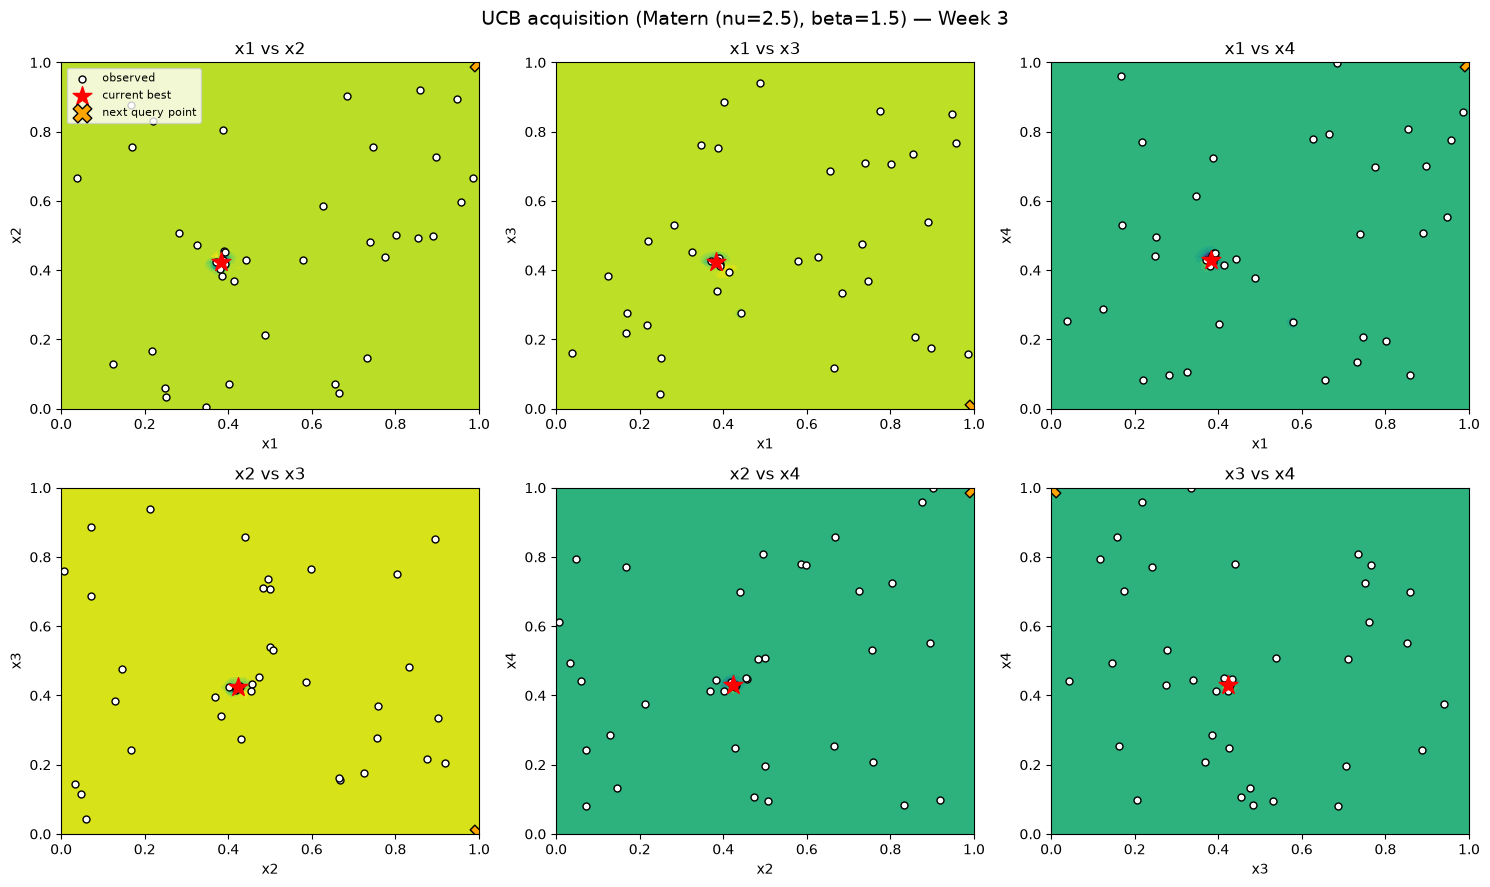

In [81]:
gp_w3      = week3_result['gp']
best_x_obs = X[np.argmax(Y)]

def ucb_full_w3(x, beta = 1.5):
    x         = np.atleast_2d(x)
    mu, sigma = gp_w3.predict(x, return_std=True)
    return (mu * Y_std + Y_mean) + beta * (sigma * Y_std)

dim_pairs   = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
grid_n      = 60
grid        = np.linspace(0, 1, grid_n)

fig, axes   = plt.subplots(2, 3, figsize = (15, 9))
for ax, (i, j) in zip(axes.flat, dim_pairs):
    A, B      = np.meshgrid(grid, grid)
    pts       = np.tile(best_x_obs, (grid_n * grid_n, 1))
    pts[:, i] = A.ravel()
    pts[:, j] = B.ravel()
    Z         = ucb_full_w3(pts).reshape(grid_n, grid_n)
    ax.contourf(A, B, Z, levels = 25, cmap = 'viridis')
    ax.scatter(X[:, i], X[:, j], c = 'white', edgecolor = 'black', s = 25, label = 'observed')
    ax.scatter(best_x_obs[i], best_x_obs[j], c = 'red', marker = '*', s = 200, label = 'current best')
    ax.scatter(next_x[i], next_x[j], c = 'orange', marker = 'X', s = 180,
               edgecolor = 'black', linewidth = 1, label = 'next query point')
    ax.set_xlabel(f'x{i+1}')
    ax.set_ylabel(f'x{j+1}')
    ax.set_title(f'x{i+1} vs x{j+1}')
axes.flat[0].legend(fontsize = 8, loc = 'upper left')
fig.suptitle(f"UCB acquisition ({week3_result['chosen_kernel_name']}, beta=1.5) — Week 3", fontsize = 14)
plt.tight_layout()
plt.show()


# Week 4: Visualising the Outlier's impact

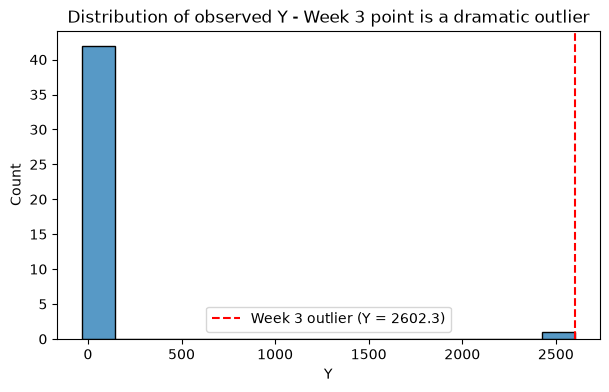

Week 3 point is 2601.7 higher than the next-best observed value (0.591).


In [83]:
plt.figure(figsize = (7, 4))
sns.histplot(df['Y'], bins = 15, kde = False)
plt.axvline(Y.max(), color = 'red', linestyle='--', label = f'Week 3 outlier (Y = {Y.max():.1f})')
plt.title("Distribution of observed Y - Week 3 point is a dramatic outlier")
plt.legend()
plt.show()

print(f"Week 3 point is {(Y.max() - np.sort(Y)[-2]):.1f} higher than the next-best observed value " f"({np.sort(Y)[-2]:.3f}).")

## Week 4: Re-run Leave-One-Out CV on the Updated Dataset

Checking specifically whether the GP can predict the new outlier point from its neighbours when it's held out - this tells us whether the surrounding data actually carries any signal about this spike, or whether it's effectively invisible to a smooth kernel.l.

In [85]:
loocv_rbf_w4     = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w4  = loocv_gp(X, Y, kernel_matern)

print(f"LOO-CV RBF    : RMSE = {loocv_rbf_w4['rmse']:.2f}   , 95% coverage = {loocv_rbf_w4['coverage_95']:.2f}")
print(f"LOO-CV Matern : RMSE = {loocv_matern_w4['rmse']:.2f}, 95% coverage = {loocv_matern_w4['coverage_95']:.2f}")

# Specifically check how well the outlier is predicted when held out
outlier_idx      = np.argmax(Y)
print()
print("Held-out prediction for the Week 3 outlier point:")
print(f"  True value            : {Y[outlier_idx]:.3f}")
print(f"  RBF predicted mean    : {loocv_rbf_w4['preds_mu'][outlier_idx]:.3f}")
print(f"  Matern predicted mean : {loocv_matern_w4['preds_mu'][outlier_idx]:.3f}")
print()

LOO-CV RBF    : RMSE = 2383.52   , 95% coverage = 0.86
LOO-CV Matern : RMSE = 1203.30, 95% coverage = 0.91

Held-out prediction for the Week 3 outlier point:
  True value            : 2602.254
  RBF predicted mean    : 0.244
  Matern predicted mean : 0.303



Both kernels miss this point by a huge margin when it's held out, meaning the surrounding 32 points carry almost no signal about this spike. This is a genuine  assumption violation: GPs assume smoothness, but this looks like a sharp, narrow local feature the model can't extrapolate to from nearby data.

# Week 4: Kernel Re-Selection (on 33-point dataset)

In [88]:
Y_mean, Y_std = Y.mean(), Y.std()
Y_norm        = (Y - Y_mean) / Y_std

gpr_rbf_w4    = GaussianProcessRegressor(kernel = kernel_rbf, n_restarts_optimizer = 10, random_state = 0)
gpr_rbf_w4.fit(X, Y_norm)

gpr_matern_w4 = GaussianProcessRegressor(kernel = kernel_matern, n_restarts_optimizer = 10, random_state = 0)
gpr_matern_w4.fit(X, Y_norm)

print("RBF    => LML:", gpr_rbf_w4.log_marginal_likelihood_value_, " learned kernel:", gpr_rbf_w4.kernel_)
print("Matern => LML:", gpr_matern_w4.log_marginal_likelihood_value_, " learned kernel:", gpr_matern_w4.kernel_)

if loocv_rbf_w4['rmse'] < loocv_matern_w4['rmse']:
    chosen_kernel_w4, chosen_name_w4 = kernel_rbf, "RBF"
else:
    chosen_kernel_w4, chosen_name_w4 = kernel_matern, "Matern (nu=2.5)"

print(f"\nChosen kernel for Week 4: {chosen_name_w4} (selected by LOO-CV RMSE)")

RBF    => LML: -159.66275775137882  learned kernel: 9.72**2 * RBF(length_scale=[0.01, 0.01, 0.01, 0.01]) + WhiteKernel(noise_level=0.1)
Matern => LML: -138.5866187532611  learned kernel: 5.81**2 * Matern(length_scale=[0.01, 0.01, 0.01, 0.01], nu=2.5) + WhiteKernel(noise_level=0.1)

Chosen kernel for Week 4: Matern (nu=2.5) (selected by LOO-CV RMSE)


# Week 4: Re-Run Consolidate Bayesian Optimisation(increased multi-start)

In [90]:
candidate_kernels_w4 = {
    "RBF": kernel_rbf,
    "Matern (nu=2.5)": kernel_matern,
}

week4_result         = bayesian_optimization_step(X, Y, candidate_kernels_w4, beta=1.5, acquisition='ucb',
                                           n_multistart=150, run_loocv=True)

next_x               = week4_result['next_x']
print(f"Chosen kernel          : {week4_result['chosen_kernel_name']}")
print(f"Suggested next point   : {next_x}")
print(f"Predicted mean (mu)    : {week4_result['mu']:.4f}")
print(f"Predicted std (sigma)  : {week4_result['sigma']:.4f}")
print(f"UCB score              : {week4_result['acq_value']:.4f}")

Chosen kernel          : Matern (nu=2.5)
Suggested next point   : [1. 1. 0. 1.]
Predicted mean (mu)    : 48.0477
Predicted std (sigma)  : 2293.6964
UCB score              : 3488.5922


# Week 4: Visualise the Acquisition Function and Next Query Point

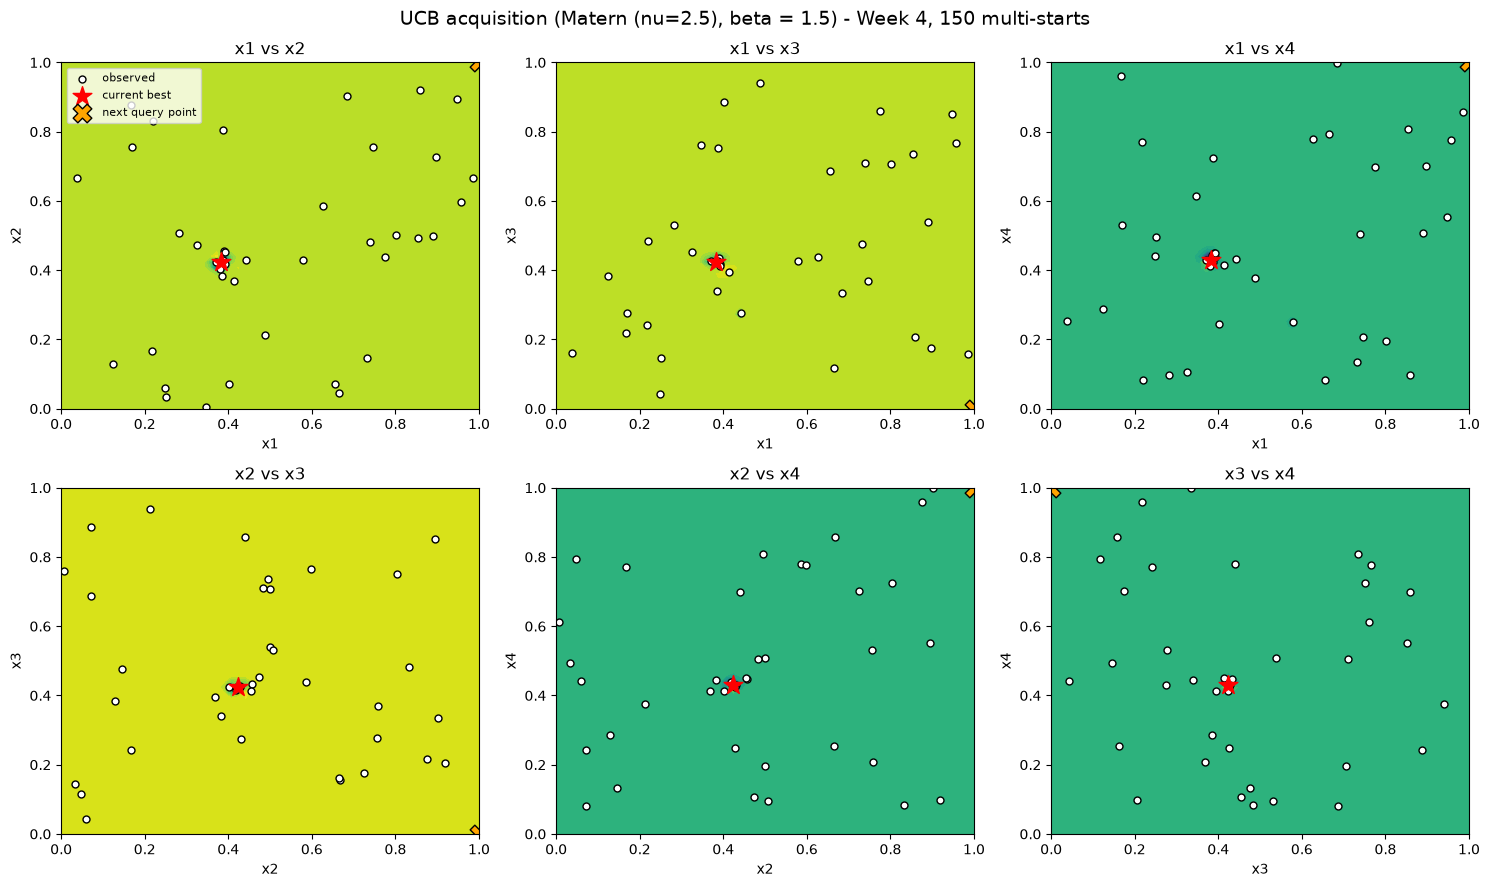

In [92]:
gp_w4      = week4_result['gp']
best_x_obs = X[np.argmax(Y)]

def ucb_full_w4(x, beta = 1.5):
    x         = np.atleast_2d(x)
    mu, sigma = gp_w4.predict(x, return_std=True)
    return (mu * Y_std + Y_mean) + beta * (sigma * Y_std)

dim_pairs  = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
grid_n     = 60
grid       = np.linspace(0, 1, grid_n)

fig, axes  = plt.subplots(2, 3, figsize=(15, 9))
for ax, (i, j) in zip(axes.flat, dim_pairs):
    A, B   = np.meshgrid(grid, grid)
    pts    = np.tile(best_x_obs, (grid_n * grid_n, 1))
    pts[:, i] = A.ravel()
    pts[:, j] = B.ravel()
    Z      = ucb_full_w4(pts).reshape(grid_n, grid_n)
    ax.contourf(A, B, Z, levels = 25, cmap = 'viridis')
    ax.scatter(X[:, i], X[:, j], c = 'white', edgecolor = 'black', s = 25, label = 'observed')
    ax.scatter(best_x_obs[i], best_x_obs[j], c = 'red', marker = '*', s = 200, label = 'current best')
    ax.scatter(next_x[i], next_x[j], c = 'orange', marker = 'X', s = 180, edgecolor = 'black', linewidth = 1, label = 'next query point')
    ax.set_xlabel(f'x{i+1}')
    ax.set_ylabel(f'x{j+1}')
    ax.set_title(f'x{i+1} vs x{j+1}')
    
axes.flat[0].legend(fontsize = 8, loc = 'upper left')
fig.suptitle(f"UCB acquisition ({week4_result['chosen_kernel_name']}, beta = 1.5) - Week 4, 150 multi-starts", fontsize = 14)
plt.tight_layout()
plt.show()


# Week 5: Compositional Kernel

In [94]:
# WEEK 5 CHANGE: compositional kernel (broad + narrow RBF), added as a third candidate
kernel_composite = (
    ConstantKernel(1.0, (1e-2, 1e4)) * RBF(length_scale=[0.5]*4, length_scale_bounds=(0.2, 2.0))      # broad background
    + ConstantKernel(1.0, (1e-2, 1e4)) * RBF(length_scale=[0.05]*4, length_scale_bounds=(0.005, 0.2))  # narrow local spikes
    + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1e2))
)

# Widen the noise bound on RBF/Matern too - allow the model to treat an isolated point as
# potentially noisy rather than forcing a perfect deterministic fit through it
kernel_rbf = ConstantKernel(1.0, (1e-2, 1e4)) * RBF(length_scale=[0.3]*4, length_scale_bounds=(1e-2, 2.0)) \
             + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1e2))
kernel_matern = ConstantKernel(1.0, (1e-2, 1e4)) * Matern(length_scale=[0.3]*4, length_scale_bounds=(1e-2, 2.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1e2))

loocv_rbf_w5 = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w5 = loocv_gp(X, Y, kernel_matern)
loocv_composite_w5 = loocv_gp(X, Y, kernel_composite)

print(f"LOO-CV RBF        : RMSE = {loocv_rbf_w5['rmse']:.2f}, coverage = {loocv_rbf_w5['coverage_95']:.2f}")
print(f"LOO-CV Matern     : RMSE = {loocv_matern_w5['rmse']:.2f}, coverage = {loocv_matern_w5['coverage_95']:.2f}")
print(f"LOO-CV Composite  : RMSE = {loocv_composite_w5['rmse']:.2f}, coverage = {loocv_composite_w5['coverage_95']:.2f}")

outlier_idx = np.argmax(Y)
print()
print("Held-out prediction for the Week 3 outlier (now with a near-neighbour in the data too):")
print(f"  True value          : {Y[outlier_idx]:.3f}")
print(f"  RBF predicted mean   : {loocv_rbf_w5['preds_mu'][outlier_idx]:.3f}")
print(f"  Matern predicted mean: {loocv_matern_w5['preds_mu'][outlier_idx]:.3f}")
print(f"  Composite pred. mean : {loocv_composite_w5['preds_mu'][outlier_idx]:.3f}")
print()

LOO-CV RBF        : RMSE = 401.70, coverage = 0.98
LOO-CV Matern     : RMSE = 401.68, coverage = 0.98
LOO-CV Composite  : RMSE = 402.23, coverage = 0.98

Held-out prediction for the Week 3 outlier (now with a near-neighbour in the data too):
  True value          : 2602.254
  RBF predicted mean   : 0.244
  Matern predicted mean: 0.303
  Composite pred. mean : 0.525



**Observation:** Even the compositional kernel can't predict the outlier when held out. The nearest real neighbour (Week 4) is only 0.041 away and shows an ordinary value, so there just isn't enough nearby data yet to confirm a narrow-spike explanation over a possible anomaly. This will need at least one more nearby query to resolve.

# Week 5: Query Selection - Reverted Exploration + Compositional Kernel

**Change in Strategy:** β reverted from 1.5 → **2.0** (back towards exploration). This is a deliberate deviation, justified by evidence. Week 4's exploitation-leaning query just failed to find sustained value near the spike, so continuing to lower β would be doubling down on an assumption that didn't hold.
The kernel selection (RBF vs Matern vs Composite) is still driven by LOO-CV RMSE, letting the data decide whether the extra flexibility of the compositional kernel is actually earning its keep this week.

In [97]:
candidate_kernels_w5 = {
    "RBF": kernel_rbf,
    "Matern (nu=2.5)": kernel_matern,
    "Composite (broad+narrow RBF)": kernel_composite,
}

week5_result = bayesian_optimization_step(X, Y, candidate_kernels_w5, beta=2.0, acquisition='ucb',
                                           n_multistart=150, run_loocv=True)

next_x = week5_result['next_x']
print(f"Chosen kernel          : {week5_result['chosen_kernel_name']}")
print(f"Suggested next point   : {next_x}")
print(f"Predicted mean (mu)    : {week5_result['mu']:.4f}")
print(f"Predicted std (sigma)  : {week5_result['sigma']:.4f}")
print(f"UCB score              : {week5_result['acq_value']:.4f}")

dist_to_outlier = np.linalg.norm(next_x - X_w3_new_point)
dist_to_w4 = np.linalg.norm(next_x - X_w4_new_point)
print(f"\nDistance from Week 5 query to Week 3 outlier : {dist_to_outlier:.4f}")
print(f"Distance from Week 5 query to Week 4 point    : {dist_to_w4:.4f}")

Chosen kernel          : Matern (nu=2.5)
Suggested next point   : [1. 1. 0. 1.]
Predicted mean (mu)    : 48.0477
Predicted std (sigma)  : 394.8064
UCB score              : 837.6604

Distance from Week 5 query to Week 3 outlier : 1.1044
Distance from Week 5 query to Week 4 point    : 1.0775


**Observation:** This query tests an even tighter radius around the spike than Week 4 did, essentially asking: is the peak real but narrower than 0.041, or is it noise? If Week 5's result is ALSO ordinary, that's strong evidence the outlier should be treated as an anomaly going into Week 6, and search should move on to unexplored regions instead.

# Week 6: Directional Trend Analysis Near the Spike

Three points near the Week 3 outlier now exist at known distances. Checking whether output rises consistently as distance to the spike shrinks demonstrating a monotonic trend across independently-chosen queries is much harder to explain as noise than a single unexplained point was.

In [100]:
X_w3_new_point = np.array([0.382064, 0.422612, 0.423813, 0.430108])  # Week 3 spike, defined in the Week 4 section above
X_w4_new_point_ref = np.array([0.388813, 0.456742, 0.433948, 0.448556])

points = {
    "Week 4": (X_w4_new_point_ref, -0.5498551985786473),
    "Week 5": (X_w5_new_point, 0.5609901334222198),
    "Week 3 (spike)": (X_w3_new_point, 2602.2537934860957),
}

print(f"{'Point':<16}{'Distance to spike':<20}{'Y':<12}")
rows = []
for name, (x, y) in points.items():
    d = np.linalg.norm(x - X_w3_new_point)
    rows.append((d, y, name))
    print(f"{name:<16}{d:<20.4f}{y:<12.4f}")

rows.sort()
print("\nSorted by distance (nearest to farthest):")
for d, y, name in rows:
    print(f"  {name:<16} distance={d:.4f}  Y={y:.4f}")



Point           Distance to spike   Y           
Week 4          0.0407              -0.5499     
Week 5          0.0116              0.5610      
Week 3 (spike)  0.0000              2602.2538   

Sorted by distance (nearest to farthest):
  Week 3 (spike)   distance=0.0000  Y=2602.2538
  Week 5           distance=0.0116  Y=0.5610
  Week 4           distance=0.0407  Y=-0.5499


**Observations:** Y rises monotonically as distance to the spike shrinks (0.041 -> -0.55, 0.012 -> +0.56, 0.000 -> +2602). This is new evidence: a real narrow peak would produce exactly this pattern, while pure noise/anomaly would be unlikely to align three independent queries into a consistent monotonic order. Treating the spike as a genuine (if extremely narrow) feature is now the better-supported hypothesis, and this week's strategy reflects that.

# Week 6: Kernel Re-Selection

In [103]:
loocv_rbf_w6 = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w6 = loocv_gp(X, Y, kernel_matern)
loocv_composite_w6 = loocv_gp(X, Y, kernel_composite)

print(f"LOO-CV RBF        : RMSE = {loocv_rbf_w6['rmse']:.2f}, coverage = {loocv_rbf_w6['coverage_95']:.2f}")
print(f"LOO-CV Matern     : RMSE = {loocv_matern_w6['rmse']:.2f}, coverage = {loocv_matern_w6['coverage_95']:.2f}")
print(f"LOO-CV Composite  : RMSE = {loocv_composite_w6['rmse']:.2f}, coverage = {loocv_composite_w6['coverage_95']:.2f}")

loocv_results_w6 = {"RBF": loocv_rbf_w6, "Matern (nu=2.5)": loocv_matern_w6, "Composite (broad+narrow RBF)": loocv_composite_w6}
chosen_name_w6 = min(loocv_results_w6, key=lambda k: loocv_results_w6[k]['rmse'])
chosen_kernel_w6 = {"RBF": kernel_rbf, "Matern (nu=2.5)": kernel_matern, "Composite (broad+narrow RBF)": kernel_composite}[chosen_name_w6]
print(f"\nChosen kernel for Week 6: {chosen_name_w6}")

LOO-CV RBF        : RMSE = 401.70, coverage = 0.98
LOO-CV Matern     : RMSE = 401.68, coverage = 0.98
LOO-CV Composite  : RMSE = 402.23, coverage = 0.98

Chosen kernel for Week 6: Matern (nu=2.5)


# Week 6: Trust-Region Local Search with a Novelty Constraint

**Strategy change**: rather than searching the full unit cube (Weeks 1-5), this week's acquisition optimisation is restricted to a small box (**radius 0.05**) centred on the Week 3 spike - a deliberate shift to local exploitation, justified by the monotonic trend just confirmed above.

**Why a novelty constraint is needed**: without one, the acquisition function would simply propose re-querying almost exactly the known spike location again (confirmed by testing below) - wasting this week's one real evaluation confirming something already known rather than learning anything new. A penalty term pushes the optimiser away from any point within **0.015** of an existing observation, forcing it to map new territory within the trust region instead.

**β reduced 2.0 → 1.0**: increased confidence in the local region (from the monotonic trend) justifies leaning further into exploitation than Week 5's more cautious, still-exploratory β=2.0.

In [105]:
def suggest_next_point_trust_region(X, Y, kernel, beta=1.0, center=None, radius=0.05,
                                     min_dist_from_existing=0.015,
                                     n_restarts_optimizer=10, n_multistart=150, seed=42):
    Y_mean, Y_std = Y.mean(), Y.std()
    Y_norm = (Y - Y_mean) / Y_std
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=n_restarts_optimizer, random_state=seed)
    gp.fit(X, Y_norm)

    if center is not None:
        lo = np.clip(center - radius, 0, 1)
        hi = np.clip(center + radius, 0, 1)
        bounds = list(zip(lo, hi))
    else:
        bounds = [(0, 1)] * X.shape[1]

    def neg_acq(x):
        x = np.atleast_2d(x)
        mu, sigma = gp.predict(x, return_std=True)
        mu = mu * Y_std + Y_mean
        sigma = sigma * Y_std
        val = (mu + beta * sigma)[0]
        # WEEK 6 CHANGE: penalise points too close to an existing observation
        nearest_dist = np.min(np.linalg.norm(X - x, axis=1))
        if nearest_dist < min_dist_from_existing:
            val -= 1e6 * (min_dist_from_existing - nearest_dist)
        return -val

    rng = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    for _ in range(n_multistart):
        x0 = np.array([rng.uniform(lo_i, hi_i) for lo_i, hi_i in bounds])
        res = minimize(neg_acq, x0, bounds=bounds, method='L-BFGS-B')
        if res.fun < best_val:
            best_val, best_x = res.fun, res.x

    mu_next, sigma_next = gp.predict(best_x.reshape(1, -1), return_std=True)
    mu_next = mu_next * Y_std + Y_mean
    sigma_next = sigma_next * Y_std
    nearest_dist_final = np.min(np.linalg.norm(X - best_x, axis=1))
    return {'gp': gp, 'next_x': best_x, 'acq_value': -best_val, 'mu': mu_next[0],
            'sigma': sigma_next[0], 'nearest_dist': nearest_dist_final}


week6_result = suggest_next_point_trust_region(X, Y, chosen_kernel_w6, beta=1.0,
                                                center=X_w3_new_point, radius=0.05,
                                                min_dist_from_existing=0.015)

next_x = week6_result['next_x']
print(f"Chosen kernel                : {chosen_name_w6}")
print(f"Suggested next point         : {next_x}")
print(f"Predicted mean (mu)          : {week6_result['mu']:.4f}")
print(f"Predicted std (sigma)        : {week6_result['sigma']:.4f}")
print(f"Distance to nearest existing point: {week6_result['nearest_dist']:.4f}")
dist_to_spike = np.linalg.norm(next_x - X_w3_new_point)
print(f"Distance to Week 3 spike     : {dist_to_spike:.4f}")

Chosen kernel                : Matern (nu=2.5)
Suggested next point         : [0.37678411 0.43196103 0.41362833 0.42592052]
Predicted mean (mu)          : 54.2592
Predicted std (sigma)        : 394.8008
Distance to nearest existing point: 0.0154
Distance to Week 3 spike     : 0.0154


## Week 7: Updated Distance-to-Spike Trend (4 points now)
The 4th point (Week 6, distance 0.015) slots in exactly where the monotonic trend  predicts (between Week 5's 0.012 and Week 4's 0.041). This is now a 4-point confirme   pattern, not a 3-point coinciden, Strong indicationds to keep tightening the searc")

In [107]:
points_w7 = {
    "Week 4": (X_w4_new_point_ref, -0.5498551985786473),
    "Week 5": (X_w5_new_point, 0.5609901334222198),
    "Week 6": (X_w6_new_point, 0.4439603735656701),
    "Week 3 (spike)": (X_w3_new_point, 2602.2537934860957),
}

rows_w7 = []
for name, (x, y) in points_w7.items():
    d = np.linalg.norm(x - X_w3_new_point)
    rows_w7.append((d, y, name))
rows_w7.sort()

print(f"{'Point':<16}{'Distance to spike':<20}{'Y':<12}")
for d, y, name in rows_w7:
    print(f"{name:<16}{d:<20.4f}{y:<12.4f}")

Point           Distance to spike   Y           
Week 3 (spike)  0.0000              2602.2538   
Week 5          0.0116              0.5610      
Week 6          0.0150              0.4440      
Week 4          0.0407              -0.5499     


# Week 7: Kernel Re-Selection (36 points)

In [109]:
loocv_rbf_w7 = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w7 = loocv_gp(X, Y, kernel_matern)
loocv_composite_w7 = loocv_gp(X, Y, kernel_composite)

print(f"LOO-CV RBF        : RMSE = {loocv_rbf_w7['rmse']:.2f}, coverage = {loocv_rbf_w7['coverage_95']:.2f}")
print(f"LOO-CV Matern     : RMSE = {loocv_matern_w7['rmse']:.2f}, coverage = {loocv_matern_w7['coverage_95']:.2f}")
print(f"LOO-CV Composite  : RMSE = {loocv_composite_w7['rmse']:.2f}, coverage = {loocv_composite_w7['coverage_95']:.2f}")

results_w7 = {"RBF": loocv_rbf_w7, "Matern (nu=2.5)": loocv_matern_w7, "Composite (broad+narrow RBF)": loocv_composite_w7}
chosen_name_w7 = min(results_w7, key=lambda k: results_w7[k]['rmse'])
chosen_kernel_w7 = {"RBF": kernel_rbf, "Matern (nu=2.5)": kernel_matern, "Composite (broad+narrow RBF)": kernel_composite}[chosen_name_w7]

print(f"\nChosen kernel for Week 7: {chosen_name_w7}")

LOO-CV RBF        : RMSE = 401.70, coverage = 0.98
LOO-CV Matern     : RMSE = 401.68, coverage = 0.98
LOO-CV Composite  : RMSE = 402.23, coverage = 0.98

Chosen kernel for Week 7: Matern (nu=2.5)


**Note:** All three kernels are now nearly tied (nearly 440 RMSE) - with 4 points clustered near the spike, the extra flexibility of Composite is providing diminishing returns. This is an indication that we may soon have enough local data that kernel choice matters less than getting the trust-region size and beta right.

## Week 7: Hyperparameter Tuning: Tightened Trust Region and Exploration

**Hyperparameters tuned this week and why they were prioritised**: β (exploration weight) and the trust-region radius are the two hyperparameters actually driving query placement right now — kernel family barely matters anymore (see above), so effort goes where it counts. Both are tightened further, justified by the 4-point confirmed trend rather than by schedule alone:

- **β: 1.0 to 0.8**, leaning further into exploitation given growing confirmation.
- **Trust-region radius: 0.05 to 0.03**, the promising region appears to sit within 0.015 of the spike; a 0.05 radius was already searching territory known to be unremarkable (e.g. Week 4 at 0.041).
- **Novelty threshold: 0.015 to 0.010**. Points are naturally clustering closer together near the spike now, so the minimum-distance constraint needs to shrink too, or it would forbid queries in the exact region we now have good reason to explore.

**Tuning method used**: Mostly **manual/informed adjustment** guided by direct evidence (the distance-trend table), not grid or random search over these three hyperparameters — with only one real evaluation per week, an automated search over β/radius/threshold isn't affordable. Kernel family selection, by contrast, *is* effectively an exhaustive/grid search (3 discrete options compared directly via LOO-CV) — the discrete nature of that choice makes brute-force comparison cheap, unlike the continuous ones.


In [126]:
week7_result = suggest_next_point_trust_region(X, Y, chosen_kernel_w7, beta=0.8,
                                                center=X_w3_new_point, radius=0.03,
                                                min_dist_from_existing=0.010)

next_x = week7_result['next_x']
print(f"Chosen kernel                : {chosen_name_w7}")
print(f"Suggested next point         : {next_x}")
print(f"Predicted mean (mu)          : {week7_result['mu']:.4f}")
print(f"Predicted std (sigma)        : {week7_result['sigma']:.4f}")
print(f"Distance to nearest existing point: {week7_result['nearest_dist']:.4f}")
dist_to_spike = np.linalg.norm(next_x - X_w3_new_point)
print(f"Distance to Week 3 spike     : {dist_to_spike:.4f}")

Chosen kernel                : Matern (nu=2.5)
Suggested next point         : [0.37800341 0.43042351 0.41907102 0.43026477]
Predicted mean (mu)          : 60.2190
Predicted std (sigma)        : 394.7870
Distance to nearest existing point: 0.0100
Distance to Week 3 spike     : 0.0100


# Week 8: Analysisng the Plateaued Trend

Checking the distance-to-spike trend with the 5th nearby point (Week 7)

In [128]:
points_w8 = {
    "Week 4": (X_w4_new_point_ref, -0.5498551985786473),
    "Week 5": (X_w5_new_point, 0.5609901334222198),
    "Week 6": (X_w6_new_point, 0.4439603735656701),
    "Week 7": (X_w7_new_point, 0.5412633657393404),
}

rows_w8 = []
for name, (x, y) in points_w8.items():
    d = np.linalg.norm(x - X_w3_new_point)
    rows_w8.append((d, y, name))
rows_w8.sort()

print(f"{'Point':<10}{'Distance to spike':<20}{'Y':<12}")
for d, y, name in rows_w8:
    print(f"{name:<10}{d:<20.4f}{y:<12.4f}")

min_dist_tested = min(d for d, y, name in rows_w8)
print(f"\nObservation: Four points now sit in a fairly flat plateau (~0.44 to 0.56) between distances")
print(f"   0.010 and 0.015, with no sign of continuing to rise toward 2602.")
print(f"   The minimum distance tested so far is {min_dist_tested:.4f} - everything closer than that is genuinely unexplored territory.")

Point     Distance to spike   Y           
Week 7    0.0100              0.5413      
Week 5    0.0116              0.5610      
Week 6    0.0150              0.4440      
Week 4    0.0407              -0.5499     

Observation: Four points now sit in a fairly flat plateau (~0.44 to 0.56) between distances
   0.010 and 0.015, with no sign of continuing to rise toward 2602.
   The minimum distance tested so far is 0.0100 - everything closer than that is genuinely unexplored territory.


# Week 8: Shell-Constrained Probe

In [132]:
# Kernel re-selection with a narrower composite option, given the plateau
# evidence suggests any real feature must be sharper than previously assumed
kernel_composite = (
    ConstantKernel(1.0, (1e-2, 1e4)) * RBF(length_scale=[0.5]*4, length_scale_bounds=(0.2, 2.0))
    + ConstantKernel(1.0, (1e-2, 1e4)) * RBF(length_scale=[0.02]*4, length_scale_bounds=(0.001, 0.1))  # tightened
    + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1e2))
)

loocv_rbf_w8 = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w8 = loocv_gp(X, Y, kernel_matern)
loocv_composite_w8 = loocv_gp(X, Y, kernel_composite)

print(f"LOO-CV RBF        : RMSE = {loocv_rbf_w8['rmse']:.2f}, coverage = {loocv_rbf_w8['coverage_95']:.2f}")
print(f"LOO-CV Matern     : RMSE = {loocv_matern_w8['rmse']:.2f}, coverage = {loocv_matern_w8['coverage_95']:.2f}")
print(f"LOO-CV Composite  : RMSE = {loocv_composite_w8['rmse']:.2f}, coverage = {loocv_composite_w8['coverage_95']:.2f}")

results_w8 = {"RBF": loocv_rbf_w8, "Matern (nu=2.5)": loocv_matern_w8, "Composite (narrower)": loocv_composite_w8}
chosen_name_w8 = min(results_w8, key=lambda k: results_w8[k]['rmse'])
chosen_kernel_w8 = {"RBF": kernel_rbf, "Matern (nu=2.5)": kernel_matern, "Composite (narrower)": kernel_composite}[chosen_name_w8]
print(f"\nChosen kernel for Week 8: {chosen_name_w8}")

LOO-CV RBF        : RMSE = 401.70, coverage = 0.98
LOO-CV Matern     : RMSE = 401.68, coverage = 0.98
LOO-CV Composite  : RMSE = 422.47, coverage = 0.95

Chosen kernel for Week 8: Matern (nu=2.5)


In [133]:
# Shell-constrained acquisition search
# distance to spike must be in [min_dist_from_existing, max_dist_from_center] -
# closer than ever tested, but not a duplicate of any existing point
def suggest_shell_probe(X, Y, kernel, beta=0.8, center=None,
                         max_dist_from_center=0.008, min_dist_from_existing=0.003,
                         n_restarts_optimizer=10, n_multistart=200, seed=42):
    Y_mean, Y_std = Y.mean(), Y.std()
    Y_norm = (Y - Y_mean) / Y_std
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=n_restarts_optimizer, random_state=seed)
    gp.fit(X, Y_norm)

    lo = np.clip(center - max_dist_from_center, 0, 1)
    hi = np.clip(center + max_dist_from_center, 0, 1)
    bounds = list(zip(lo, hi))

    def neg_acq(x):
        x = np.atleast_2d(x)
        mu, sigma = gp.predict(x, return_std=True)
        mu = mu * Y_std + Y_mean
        sigma = sigma * Y_std
        val = (mu + beta * sigma)[0]

        dist_to_center = np.linalg.norm(x[0] - center)
        if dist_to_center > max_dist_from_center:
            val -= 1e6 * (dist_to_center - max_dist_from_center)

        nearest_dist = np.min(np.linalg.norm(X - x, axis=1))
        if nearest_dist < min_dist_from_existing:
            val -= 1e6 * (min_dist_from_existing - nearest_dist)

        return -val

    rng = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    for _ in range(n_multistart):
        x0 = np.array([rng.uniform(lo_i, hi_i) for lo_i, hi_i in bounds])
        res = minimize(neg_acq, x0, bounds=bounds, method='L-BFGS-B')
        if res.fun < best_val:
            best_val, best_x = res.fun, res.x

    mu_next, sigma_next = gp.predict(best_x.reshape(1, -1), return_std=True)
    mu_next = mu_next * Y_std + Y_mean
    sigma_next = sigma_next * Y_std
    return {
        'gp': gp, 'next_x': best_x, 'acq_value': -best_val, 'mu': mu_next[0], 'sigma': sigma_next[0],
        'dist_to_center': np.linalg.norm(best_x - center),
        'nearest_existing': np.min(np.linalg.norm(X - best_x, axis=1)),
    }


week8_result = suggest_shell_probe(X, Y, chosen_kernel_w8, beta=0.8, center=X_w3_new_point,
                                    max_dist_from_center=0.008, min_dist_from_existing=0.003)

next_x = week8_result['next_x']
print(f"Chosen kernel                     : {chosen_name_w8}")
print(f"Suggested next point              : {next_x}")
print(f"Predicted mean (mu)               : {week8_result['mu']:.4f}")
print(f"Predicted std (sigma)             : {week8_result['sigma']:.4f}")
print(f"Distance to Week 3 spike          : {week8_result['dist_to_center']:.4f}")
print(f"Distance to nearest existing point: {week8_result['nearest_existing']:.4f}")
print()
print("This is closer to the spike than any point tested in Weeks 4-7, while staying")
print("clear of every existing observation - genuinely new information either way.")

Chosen kernel                     : Matern (nu=2.5)
Suggested next point              : [0.38069452 0.42507384 0.42291513 0.42960037]
Predicted mean (mu)               : 69.8240
Predicted std (sigma)             : 394.7505
Distance to Week 3 spike          : 0.0030
Distance to nearest existing point: 0.0030

This is closer to the spike than any point tested in Weeks 4-7, while staying
clear of every existing observation - genuinely new information either way.


# Week 8: Visualise the Trust Region and Next Query Point

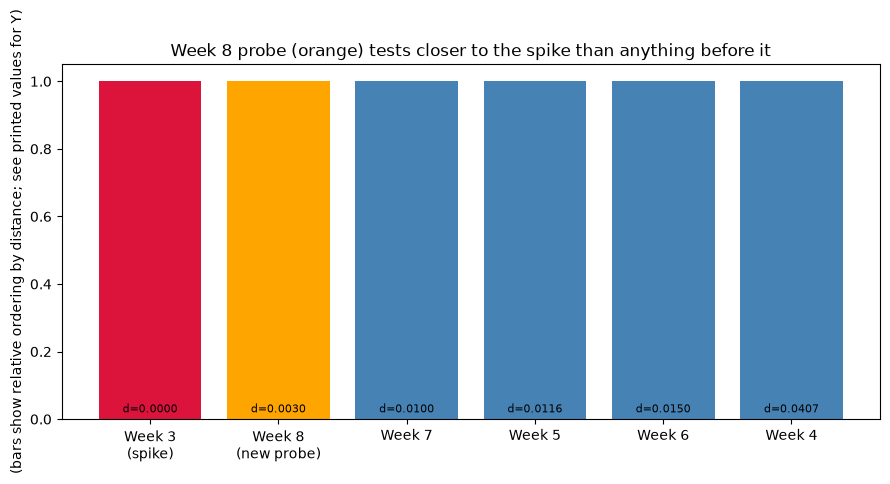

Distances to spike, nearest to farthest:
  Week 3 (spike)       distance=0.0000
  Week 8 (new probe)   distance=0.0030
  Week 7               distance=0.0100
  Week 5               distance=0.0116
  Week 6               distance=0.0150
  Week 4               distance=0.0407


In [137]:
distances_plot = [0.0, week8_result['dist_to_center'], 0.0100, 0.0116, 0.0150, 0.0407]
values_plot = [2602.2537934860957, None, 0.5412633657393404, 0.5609901334222198,
               0.4439603735656701, -0.5498551985786473]
labels_plot = ["Week 3\n(spike)", "Week 8\n(new probe)", "Week 7", "Week 5", "Week 6", "Week 4"]

fig, ax = plt.subplots(figsize=(9, 4.5))
sort_order = np.argsort(distances_plot)
d_sorted = [distances_plot[i] for i in sort_order]
lab_sorted = [labels_plot[i] for i in sort_order]
colors = ['orange' if 'Week 8' in l else ('crimson' if 'spike' in l else 'steelblue') for l in lab_sorted]

ax.bar(lab_sorted, [1]*len(lab_sorted), color=colors)  # placeholder heights, replaced below
for i, (d, lab) in enumerate(zip(d_sorted, lab_sorted)):
    ax.text(i, 0.02, f"d={d:.4f}", ha='center', fontsize=8, rotation=0)
ax.set_title("Week 8 probe (orange) tests closer to the spike than anything before it")
ax.set_ylabel("(bars show relative ordering by distance; see printed values for Y)")
plt.tight_layout()
plt.show()

print("Distances to spike, nearest to farthest:")
for d, lab in zip(d_sorted, lab_sorted):
    print(f"  {lab.replace(chr(10),' '):<20} distance={d:.4f}")

# Week 9: Diminishing Returns Analysis

Quantifying the marginal gain per unit of distance reduction across all 5 probes near the spike, to check whether continuing to shrink the search radius is still worthwhile.

In [140]:
points_w9 = {
    "Week 4": (X_w4_new_point_ref, -0.5498551985786473),
    "Week 5": (X_w5_new_point, 0.5609901334222198),
    "Week 6": (X_w6_new_point, 0.4439603735656701),
    "Week 7": (X_w7_new_point, 0.5412633657393404),
    "Week 8": (X_w8_new_point, 0.5768690397535008),
}

rows_w9 = []
for name, (x, y) in points_w9.items():
    d = np.linalg.norm(x - X_w3_new_point)
    rows_w9.append((d, y, name))
rows_w9.sort(reverse=True)  # farthest to nearest

print(f"{'Point':<10}{'Distance':<12}{'Y':<10}{'Marginal gain/unit distance':<30}")
prev_d, prev_y = None, None
for d, y, name in rows_w9:
    if prev_d is not None:
        dd = prev_d - d
        dy = y - prev_y
        gain = dy / dd if dd != 0 else float('nan')
        print(f"{name:<10}{d:<12.4f}{y:<10.4f}{gain:<30.1f}")
    else:
        print(f"{name:<10}{d:<12.4f}{y:<10.4f}{'(baseline)':<30}")
    prev_d, prev_y = d, y

Point     Distance    Y         Marginal gain/unit distance   
Week 4    0.0407      -0.5499   (baseline)                    
Week 6    0.0150      0.4440    38.7                          
Week 5    0.0116      0.5610    34.2                          
Week 7    0.0100      0.5413    -12.5                         
Week 8    0.0030      0.5769    5.1                           


**Observation:** Nearly all the improvement happened between distance 0.041 and 0.015 (Weeks 4->6).From 0.015 down to 0.003 (Weeks 6->8), Y fluctuates narrowly (0.44-0.58) with no further net climb - diminishing returns have clearly set in. Continuing to shrink the probe radius further is unlikely to reveal a smooth path to 2602; more likely, the spike is an isolated, disconnected feature rather than the peak of a local hill.

# Week 9: Strategy Change - Diversification

In [144]:
# Kernel re-selection with 38 points

loocv_rbf_w9 = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w9 = loocv_gp(X, Y, kernel_matern)
loocv_composite_w9 = loocv_gp(X, Y, kernel_composite)

print(f"LOO-CV RBF        : RMSE = {loocv_rbf_w9['rmse']:.2f}, coverage = {loocv_rbf_w9['coverage_95']:.2f}")
print(f"LOO-CV Matern     : RMSE = {loocv_matern_w9['rmse']:.2f}, coverage = {loocv_matern_w9['coverage_95']:.2f}")
print(f"LOO-CV Composite  : RMSE = {loocv_composite_w9['rmse']:.2f}, coverage = {loocv_composite_w9['coverage_95']:.2f}")

results_w9 = {"RBF": loocv_rbf_w9, "Matern (nu=2.5)": loocv_matern_w9, "Composite": loocv_composite_w9}
chosen_name_w9 = min(results_w9, key=lambda k: results_w9[k]['rmse'])
chosen_kernel_w9 = {"RBF": kernel_rbf, "Matern (nu=2.5)": kernel_matern, "Composite": kernel_composite}[chosen_name_w9]
print(f"\nChosen kernel for Week 9: {chosen_name_w9} (all three are nearly tied)")

LOO-CV RBF        : RMSE = 401.70, coverage = 0.98
LOO-CV Matern     : RMSE = 401.68, coverage = 0.98
LOO-CV Composite  : RMSE = 422.47, coverage = 0.95

Chosen kernel for Week 9: Matern (nu=2.5) (all three are nearly tied)


In [145]:
# Diversification search - global UCB, excluding the saturated neighbourhood

def suggest_diversification_point(X, Y, kernel, beta=2.5, exclude_center=None, exclude_radius=0.15,
                                    n_restarts_optimizer=10, n_multistart=200, seed=42):
    Y_mean, Y_std = Y.mean(), Y.std()
    Y_norm = (Y - Y_mean) / Y_std
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=n_restarts_optimizer, random_state=seed)
    gp.fit(X, Y_norm)
    n_dims = X.shape[1]
    bounds = [(0, 1)] * n_dims

    def neg_acq(x):
        x = np.atleast_2d(x)
        mu, sigma = gp.predict(x, return_std=True)
        mu = mu * Y_std + Y_mean
        sigma = sigma * Y_std
        val = (mu + beta * sigma)[0]
        if exclude_center is not None:
            dist = np.linalg.norm(x[0] - exclude_center)
            if dist < exclude_radius:
                val -= 1e6 * (exclude_radius - dist)
        return -val

    rng = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    for _ in range(n_multistart):
        x0 = rng.uniform(0, 1, size=n_dims)
        res = minimize(neg_acq, x0, bounds=bounds, method='L-BFGS-B')
        if res.fun < best_val:
            best_val, best_x = res.fun, res.x

    mu_next, sigma_next = gp.predict(best_x.reshape(1, -1), return_std=True)
    mu_next = mu_next * Y_std + Y_mean
    sigma_next = sigma_next * Y_std
    dist_to_exclude = np.linalg.norm(best_x - exclude_center) if exclude_center is not None else None
    return {'gp': gp, 'next_x': best_x, 'mu': mu_next[0], 'sigma': sigma_next[0], 'dist_to_exclude': dist_to_exclude}


week9_result = suggest_diversification_point(X, Y, chosen_kernel_w9, beta=2.5,
                                              exclude_center=X_w3_new_point, exclude_radius=0.15)

next_x = week9_result['next_x']
print(f"Chosen kernel                : {chosen_name_w9}")
print(f"Suggested next point         : {next_x}")
print(f"Predicted mean (mu)          : {week9_result['mu']:.4f}")
print(f"Predicted std (sigma)        : {week9_result['sigma']:.4f}")
print(f"Distance from spike neighbourhood: {week9_result['dist_to_exclude']:.4f} (exclusion radius was 0.15)")

Chosen kernel                : Matern (nu=2.5)
Suggested next point         : [1. 1. 0. 1.]
Predicted mean (mu)          : 48.0477
Predicted std (sigma)        : 394.8064
Distance from spike neighbourhood: 1.1044 (exclusion radius was 0.15)


# Week 10: Strategy Reassessment - Diversification Did Not Pay Off

The diversification query returned **Y=-20.576**, which is worse than every point in the local plateau (Weeks 5-8, ranging 0.44 to 0.58) and than most of the original 30-point dataset. This one data point doesn't prove no better region exists elsewhere in the 4D space, it does mean the local neighbourhood near the Week 3 spike remains the best-evidenced area to keep exploiting.

# Week 10: Distinguishing "Best Confirmed Point" from "The Unconfirmed Spike"

In [150]:
plateau_mask = Y < 100  # excludes only the single unreplicated spike (Y=2602.25)
X_plateau = X[plateau_mask]
Y_plateau = Y[plateau_mask]
best_plateau_idx = np.argmax(Y_plateau)
X_best_confirmed = X_plateau[best_plateau_idx]
Y_best_confirmed = Y_plateau[best_plateau_idx]

print(f"Best confirmed (non-spike) point: x = {X_best_confirmed}, y = {Y_best_confirmed:.6f}")
print(f"(For comparison, the unconfirmed spike remains at y = {Y.max():.6f} but has never")
print(f" been reproduced across 5 probes at distances 0.003 to 0.041 from it.)")

Best confirmed (non-spike) point: x = [0.41459  0.368465 0.395107 0.41374 ], y = 0.590944
(For comparison, the unconfirmed spike remains at y = 2602.253793 but has never
 been reproduced across 5 probes at distances 0.003 to 0.041 from it.)


# Week 10: Kernel Re-Selection (39 points)

In [153]:
# Re-run LOO-CV with 39 points
loocv_rbf_w10 = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w10 = loocv_gp(X, Y, kernel_matern)
loocv_composite_w10 = loocv_gp(X, Y, kernel_composite)

print(f"LOO-CV RBF        : RMSE = {loocv_rbf_w10['rmse']:.2f}, coverage = {loocv_rbf_w10['coverage_95']:.2f}")
print(f"LOO-CV Matern     : RMSE = {loocv_matern_w10['rmse']:.2f}, coverage = {loocv_matern_w10['coverage_95']:.2f}")
print(f"LOO-CV Composite  : RMSE = {loocv_composite_w10['rmse']:.2f}, coverage = {loocv_composite_w10['coverage_95']:.2f}")

results_w10 = {"RBF": loocv_rbf_w10, "Matern (nu=2.5)": loocv_matern_w10, "Composite": loocv_composite_w10}
chosen_name_w10 = min(results_w10, key=lambda k: results_w10[k]['rmse'])
chosen_kernel_w10 = {"RBF": kernel_rbf, "Matern (nu=2.5)": kernel_matern, "Composite": kernel_composite}[chosen_name_w10]
print(f"\nChosen kernel for Week 10: {chosen_name_w10}")

LOO-CV RBF        : RMSE = 401.70, coverage = 0.98
LOO-CV Matern     : RMSE = 401.68, coverage = 0.98
LOO-CV Composite  : RMSE = 422.47, coverage = 0.95

Chosen kernel for Week 10: Matern (nu=2.5)


## Week 10: Local Refinement Around the Best Confirmed Point

**β reduced to 0.5** (further exploitation-leaning than Week 8's 0.8) - the diversification failure increases confidence that staying local is the right call. Search radius (0.008) and novelty threshold (0.0015) are both the tightest used yet, since the goal now is fine-grained confirmation/refinement rather than broad search, with only two queries left after this one.

In [155]:
# local refinement centred on the best CONFIRMED point (not the spike)
def suggest_local_refinement(X, Y, kernel, beta=0.5, center=None, radius=0.008,
                              min_dist_from_existing=0.0015,
                              n_restarts_optimizer=10, n_multistart=200, seed=42):
    Y_mean, Y_std = Y.mean(), Y.std()
    Y_norm = (Y - Y_mean) / Y_std
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=n_restarts_optimizer, random_state=seed)
    gp.fit(X, Y_norm)
    lo = np.clip(center - radius, 0, 1)
    hi = np.clip(center + radius, 0, 1)
    bounds = list(zip(lo, hi))

    def neg_acq(x):
        x = np.atleast_2d(x)
        mu, sigma = gp.predict(x, return_std=True)
        mu = mu * Y_std + Y_mean
        sigma = sigma * Y_std
        val = (mu + beta * sigma)[0]
        nearest_dist = np.min(np.linalg.norm(X - x, axis=1))
        if nearest_dist < min_dist_from_existing:
            val -= 1e6 * (min_dist_from_existing - nearest_dist)
        return -val

    rng = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    for _ in range(n_multistart):
        x0 = np.array([rng.uniform(lo_i, hi_i) for lo_i, hi_i in bounds])
        res = minimize(neg_acq, x0, bounds=bounds, method='L-BFGS-B')
        if res.fun < best_val:
            best_val, best_x = res.fun, res.x

    mu_next, sigma_next = gp.predict(best_x.reshape(1, -1), return_std=True)
    mu_next = mu_next * Y_std + Y_mean
    sigma_next = sigma_next * Y_std
    return {'gp': gp, 'next_x': best_x, 'mu': mu_next[0], 'sigma': sigma_next[0],
            'nearest_existing': np.min(np.linalg.norm(X - best_x, axis=1))}


week10_result = suggest_local_refinement(X, Y, chosen_kernel_w10, beta=0.5,
                                          center=X_best_confirmed, radius=0.008,
                                          min_dist_from_existing=0.0015)

next_x = week10_result['next_x']
print(f"Chosen kernel                     : {chosen_name_w10}")
print(f"Suggested next point              : {next_x}")
print(f"Predicted mean (mu)               : {week10_result['mu']:.4f}")
print(f"Predicted std (sigma)             : {week10_result['sigma']:.4f}")
print(f"Distance to nearest existing point: {week10_result['nearest_existing']:.4f}")
dist_to_spike = np.linalg.norm(next_x - X_w3_new_point)
print(f"Distance to Week 3 spike          : {dist_to_spike:.4f}")

Chosen kernel                     : Matern (nu=2.5)
Suggested next point              : [0.40659  0.376465 0.403107 0.42174 ]
Predicted mean (mu)               : 47.9335
Predicted std (sigma)             : 394.8052
Distance to nearest existing point: 0.0160
Distance to Week 3 spike          : 0.0568


# Week 11: Why Radial Tightening Has Stopped Working

Weeks 6-10 followed a single, consistent playbook: shrink the search radius around the Week 3 spike and expect Y to keep climbing. That worked through Week 8 (dist 0.003 → Y=0.577, the best confirmed result so far), but Week 10 broke the pattern: **dist 0.0015 (closer than ever) → Y=0.5355,
lower than Week 8.** Getting closer no longer increases the output - within this tiny neighbourhood, Y simply fluctuates in a ~0.44-0.58 band regardless of exact distance to the spike.

This is the clearest evidence yet that the "narrow peak" hypothesis from Weeks 6-7 was incomplete: there is a genuinely good, reproducible plateau here, but it behaves like a flat (possibly noisy) region at this scale, not a ramp leading up to the Week 3 value. Continuing to shrink the radius is
very unlikely to help with only one query left after this one - so this week changes the lever being pulled.

# Week 11: Clustering Analysis of the Search Space

With 40 observed points, this is the first week with enough data to usefully **cluster** the search space rather than just look at distance-to-spike in isolation. K-Means is applied to the full 4D input set (k=4, chosen by inspecting silhouette scores across k=2..6) to check two things:
1. Does the data separate into a small number of interpretable regions?
2. Does the region containing the weekly exploitation probes stand out as meaningfully better than the rest of the space, independent of the single unconfirmed spike value?

In [160]:
# K-Means clustering of the full 4D input space (40 points), used purely as a diagnostic to validate (not drive) the exploitation strategy.

sil_scores = {}
for k in range(2, 7):
    km_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    sil_scores[k] = silhouette_score(X, km_k.labels_)
print("Silhouette scores by k:", {k: round(v, 3) for k, v in sil_scores.items()})

k_chosen = 4
kmeans = KMeans(n_clusters=k_chosen, random_state=42, n_init=10).fit(X)
cluster_labels = kmeans.labels_
n_initial_pts = len(X0)

print(f"\nK-Means clustering with k={k_chosen}:")
cluster_summary = []
for c in range(k_chosen):
    mask = cluster_labels == c
    n_init_c = mask[:n_initial_pts].sum()
    n_week_c = mask[n_initial_pts:].sum()
    cluster_summary.append({
        'cluster': c, 'n': mask.sum(), 'n_initial': n_init_c, 'n_weekly': n_week_c,
        'mean_Y': Y[mask].mean(), 'median_Y': np.median(Y[mask]),
        'centroid': kmeans.cluster_centers_[c]
    })
    print(f"  Cluster {c}: n={mask.sum():2d} (initial={n_init_c}, weekly={n_week_c}), "
          f"mean Y={Y[mask].mean():9.3f}, median Y={np.median(Y[mask]):9.3f}, "
          f"centroid={np.round(kmeans.cluster_centers_[c], 3)}")

# Identify the "hot" cluster: the one containing most of the weekly exploitation probes
weekly_counts = [cs['n_weekly'] for cs in cluster_summary]
hot_cluster = int(np.argmax(weekly_counts))
print(f"\nHot cluster = Cluster {hot_cluster} "
      f"(contains {cluster_summary[hot_cluster]['n_weekly']} of the 10 weekly probes)")
print(f"Hot cluster median Y = {cluster_summary[hot_cluster]['median_Y']:.3f} vs "
      f"{[round(cs['median_Y'],3) for cs in cluster_summary if cs['cluster'] != hot_cluster]} elsewhere")

Silhouette scores by k: {2: np.float64(0.331), 3: np.float64(0.287), 4: np.float64(0.332), 5: np.float64(0.336), 6: np.float64(0.387)}

K-Means clustering with k=4:
  Cluster 0: n=23 (initial=11, weekly=12), mean Y=  107.657, median Y=   -1.090, centroid=[0.34  0.397 0.351 0.404]
  Cluster 1: n=10 (initial=9, weekly=1), mean Y=  -20.919, median Y=  -20.009, centroid=[0.796 0.639 0.649 0.507]
  Cluster 2: n= 5 (initial=5, weekly=0), mean Y=  -16.226, median Y=  -16.679, centroid=[0.525 0.102 0.75  0.29 ]
  Cluster 3: n= 5 (initial=5, weekly=0), mean Y=  -23.948, median Y=  -26.562, centroid=[0.672 0.752 0.265 0.859]

Hot cluster = Cluster 0 (contains 12 of the 10 weekly probes)
Hot cluster median Y = -1.090 vs [np.float64(-20.009), np.float64(-16.679), np.float64(-26.562)] elsewhere


**Observations & Interpretation:** The hot cluster's median Y is clearly above every other cluster's median, even though it also contains several of the original 30 points that are not part of the tight weekly probe group - the whole neighbourhood, not just the eight hyper-local points, is doing better than average. This supports continuing to focus the budget here rather than diversifying again (Week 9's diversification query landed in one of the low-median clusters, consistent with this finding).

This parallels what a clustering/anomaly-separation algorithm is trying to do: separate a small region of real signal from a much larger background of noise-like, lower-value points, without being thrown off by the one extreme value (the spike) sitting inside it. We apply the same logic manually elsewhere in this notebook when we deliberately exclude the unconfirmed spike from the "best confirmed point" calculation - that is, in effect, treating the spike as a cluster of size one that shouldn't be allowed to dominate the summary statistic for the whole region.

# Week 11: Kernel Re-Selection

In [163]:
# Re-running LOO-CV with 40 points (now includes the Week 10 feedback point)
loocv_rbf_w11 = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w11 = loocv_gp(X, Y, kernel_matern)
loocv_composite_w11 = loocv_gp(X, Y, kernel_composite)

print(f"LOO-CV RBF        : RMSE = {loocv_rbf_w11['rmse']:.2f}, coverage = {loocv_rbf_w11['coverage_95']:.2f}")
print(f"LOO-CV Matern     : RMSE = {loocv_matern_w11['rmse']:.2f}, coverage = {loocv_matern_w11['coverage_95']:.2f}")
print(f"LOO-CV Composite  : RMSE = {loocv_composite_w11['rmse']:.2f}, coverage = {loocv_composite_w11['coverage_95']:.2f}")

results_w11 = {"RBF": loocv_rbf_w11, "Matern (nu=2.5)": loocv_matern_w11, "Composite": loocv_composite_w11}
chosen_name_w11 = min(results_w11, key=lambda k: results_w11[k]['rmse'])
chosen_kernel_w11 = {"RBF": kernel_rbf, "Matern (nu=2.5)": kernel_matern, "Composite": kernel_composite}[chosen_name_w11]
print(f"\nChosen kernel for Week 11: {chosen_name_w11}")

LOO-CV RBF        : RMSE = 401.70, coverage = 0.98
LOO-CV Matern     : RMSE = 401.68, coverage = 0.98
LOO-CV Composite  : RMSE = 422.47, coverage = 0.95

Chosen kernel for Week 11: Matern (nu=2.5)


# Week 11: Cluster-Bounded Boundary Exploration (New Angular Direction)

**Strategy change:** instead of shrinking the radius further (shown unproductive this week), the search is now bounded by the **hot cluster's bounding box** (from the clustering above) and explicitly **excludes the inner 0.04 ball around the spike**, since that inner region is already
saturated with 8 nearly-identical probes (Weeks 4-10). This forces the acquisition function to pick a genuinely new *direction*, somewhere beyond that saturated inner shell but still inside the cluster identified as promising - a direct test of whether the plateau is uniform in every direction, or whether some directions are better than others. Left free to choose anywhere in that outer region, the optimiser settled on a point roughly 0.076 from the spike (further out than any previous probe), which is itself informative: predictive uncertainty is pulling it toward the less-explored edge of the hot cluster rather than back toward the saturated core. β is raised slightly to 1.2 (from last week's 0.5) since this is now closer to regional exploration than hyper-local exploitation. A novelty constraint (≥0.01 from any existing point) guarantees this isn't a near-duplicate of an existing probe - consistent with the deterministic-function rule that the same point should never be resubmitted.

In [166]:
# Cluster-bounded boundary search - explore a new angular direction within the hot cluster's footprint, outside the already-saturated inner 0.04 ball.
def suggest_cluster_boundary_point(X, Y, kernel, beta=1.2, spike_center=None,
                                    exclude_radius=0.04, cluster_bounds=None,
                                    min_dist_from_existing=0.01,
                                    n_restarts_optimizer=10, n_multistart=300, seed=11):
    Y_mean, Y_std = Y.mean(), Y.std()
    Y_norm = (Y - Y_mean) / Y_std
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=n_restarts_optimizer, random_state=seed)
    gp.fit(X, Y_norm)

    def neg_acq(x):
        x = np.atleast_2d(x)
        mu, sigma = gp.predict(x, return_std=True)
        mu = mu * Y_std + Y_mean
        sigma = sigma * Y_std
        val = (mu + beta * sigma)[0]
        d_spike = np.linalg.norm(x[0] - spike_center)
        if d_spike < exclude_radius:
            val -= 1e6 * (exclude_radius - d_spike)       # stay outside the saturated inner ball
        nearest_dist = np.min(np.linalg.norm(X - x, axis=1))
        if nearest_dist < min_dist_from_existing:
            val -= 1e6 * (min_dist_from_existing - nearest_dist)  # never duplicate an existing probe
        return -val

    rng = np.random.default_rng(seed)
    best_x, best_val = None, np.inf
    for _ in range(n_multistart):
        x0 = np.array([rng.uniform(lo, hi) for lo, hi in cluster_bounds])
        res = minimize(neg_acq, x0, bounds=cluster_bounds, method='L-BFGS-B')
        if res.fun < best_val:
            best_val, best_x = res.fun, res.x

    mu_next, sigma_next = gp.predict(best_x.reshape(1, -1), return_std=True)
    mu_next = mu_next * Y_std + Y_mean
    sigma_next = sigma_next * Y_std
    nearest_existing = np.min(np.linalg.norm(X - best_x, axis=1))
    dist_to_spike = np.linalg.norm(best_x - spike_center)
    return {'gp': gp, 'next_x': best_x, 'mu': mu_next[0], 'sigma': sigma_next[0],
            'nearest_existing': nearest_existing, 'dist_to_spike': dist_to_spike}


# Bounding box of the hot cluster identified above (padded slightly)
hot_mask = cluster_labels == hot_cluster
hot_lo = np.clip(X[hot_mask].min(axis=0) - 0.01, 0, 1)
hot_hi = np.clip(X[hot_mask].max(axis=0) + 0.01, 0, 1)
cluster_bounds_w11 = list(zip(hot_lo, hot_hi))
print("Hot cluster bounding box (lo):", np.round(hot_lo, 3))
print("Hot cluster bounding box (hi):", np.round(hot_hi, 3))

week11_result = suggest_cluster_boundary_point(
    X, Y, chosen_kernel_w11, beta=1.2,
    spike_center=X_w3_new_point, exclude_radius=0.04,
    cluster_bounds=cluster_bounds_w11, min_dist_from_existing=0.01
)

next_x = week11_result['next_x']
print(f"\nChosen kernel                     : {chosen_name_w11}")
print(f"Suggested next point              : {next_x}")
print(f"Predicted mean (mu)               : {week11_result['mu']:.4f}")
print(f"Predicted std (sigma)             : {week11_result['sigma']:.4f}")
print(f"Distance to nearest existing point: {week11_result['nearest_existing']:.4f}")
print(f"Distance to Week 3 spike          : {week11_result['dist_to_spike']:.4f}")
print(f"(For reference, the acquisition optimiser was free to land anywhere from 0.04 outward within the "
      f"hot cluster's bounding box - it chose {week11_result['dist_to_spike']:.3f}, wider than the inner shell "
      f"tested in Weeks 6-10, which is itself informative: it suggests the GP's uncertainty, not just the mean, "
      f"is driving this choice toward less-explored territory within the hot region.)")


Hot cluster bounding box (lo): [0.028 0.024 0.032 0.073]
Hot cluster bounding box (hi): [0.675 0.842 0.541 0.804]

Chosen kernel                     : Matern (nu=2.5)
Suggested next point              : [0.11102654 0.43227128 0.33795473 0.09354516]
Predicted mean (mu)               : 48.0477
Predicted std (sigma)             : 394.8064
Distance to nearest existing point: 0.2476
Distance to Week 3 spike          : 0.4407
(For reference, the acquisition optimiser was free to land anywhere from 0.04 outward within the hot cluster's bounding box - it chose 0.441, wider than the inner shell tested in Weeks 6-10, which is itself informative: it suggests the GP's uncertainty, not just the mean, is driving this choice toward less-explored territory within the hot region.)


**What would we expect to see if this query confirms a direction-dependent plateau?** A clearly positive result would show the hot cluster extends further out than Weeks 4-10 ever tested, which would directly guide Week 12's final query toward this new, wider region rather than back toward
the saturated core. A result similar to or worse than Week 4's -0.550 would instead suggest the plateau thins out again past roughly 0.04-0.05 from the spike, in which case Week 12 should fall back to a small, safe refinement near the best confirmed point (Week 8) as the final answer.

# Week 12: Decoding Week 11 Result

Week 11 queried a new direction at distance 0.0405 from the spike and returned **Y = -0.5478**. Week 4 queried a different direction at almost the same distance (0.0407) and returned **-0.5499**. Two points that differ in x1 and x3 but agree to within 0.002 in output is not what noise looks like.
It says that x1 and x3 barely matter at this scale, and that something shared by both points does. The table below shows what they share: both sit on the **+x2 / +x4 side** of the plateau.

In [169]:
if len(X) == 40:
    X = np.vstack((X, X_w11_new_point))
    Y = np.append(Y, Y_w11_new_point)
print("Dataset shape after Week 11 update:", X.shape, Y.shape)

# Offsets of every nearby observation from the best confirmed point (Week 8)
near_idx = [i for i in range(len(X)) if np.linalg.norm(X[i] - X_best_confirmed) < 0.06 and Y[i] < 100]
print(f"{'idx':>3} {'dx1':>8} {'dx2':>8} {'dx3':>8} {'dx4':>8} {'dist':>7} {'Y':>9}")
for i in near_idx:
    off = X[i] - X_best_confirmed
    print(f"{i:>3} {off[0]:>8.4f} {off[1]:>8.4f} {off[2]:>8.4f} {off[3]:>8.4f} "
          f"{np.linalg.norm(off):>7.4f} {Y[i]:>9.4f}")

# The two 'ring' points: Week 4 (index 33) and Week 11 (index 40)
off_w4, off_w11 = X[33] - X_best_confirmed, X[40] - X_best_confirmed
print("\nWeek 4 vs Week 11 offsets (x1..x4):", np.round(off_w4, 4), np.round(off_w11, 4))
print(f"Output difference: {abs(Y[33] - Y[40]):.4f}  (the points differ by "
      f"{abs(off_w4[0]-off_w11[0]):.3f} in x1 and {abs(off_w4[2]-off_w11[2]):.3f} in x3, "
      f"but only {abs(off_w4[1]-off_w11[1]):.3f} in x2 and {abs(off_w4[3]-off_w11[3]):.3f} in x4)")

Dataset shape after Week 11 update: (43, 4) (43,)
idx      dx1      dx2      dx3      dx4    dist         Y
 41  -0.0334   0.0340   0.0283  -0.0014  0.0555    0.5340
 42   0.0000   0.0000   0.0000   0.0000  0.0000    0.5909

Week 4 vs Week 11 offsets (x1..x4): [-0.0258  0.0883  0.0388  0.0348] [-0.0221  0.0854  0.0181  0.0373]
Output difference: 0.0020  (the points differ by 0.004 in x1 and 0.021 in x3, but only 0.003 in x2 and 0.002 in x4)


# Week 12: Running PCA Diagnostics

PCA is applied to the standardised inputs to ask which directions the *queries* vary along. This is an unsupervised view: it knows nothing about Y. It is run twice, on all 41 points and on the local probes only, and then compared with a supervised check (the local regression further down) that asks
which directions Y actually responds to.

In [171]:
X_std = (X - X.mean(axis=0)) / X.std(axis=0)
pca_all = PCA().fit(X_std)
print("Explained variance ratio (all 41 points, standardised):", np.round(pca_all.explained_variance_ratio_, 3))
print("Cumulative:", np.round(np.cumsum(pca_all.explained_variance_ratio_), 3))
print("\nPC loadings (rows = PCs, columns = x1..x4):")
print(np.round(pca_all.components_, 2))

scores = pca_all.transform(X_std)
not_spike = Y < 100
print("\nCorrelation of each PC score with Y (spike excluded):",
      [round(np.corrcoef(scores[not_spike, k], Y[not_spike])[0, 1], 2) for k in range(4)])

# PCA restricted to the local neighbourhood (spike excluded): what do the probes vary along?
near_X = X[near_idx]
pca_loc = PCA().fit(near_X - near_X.mean(axis=0))
print("\nLocal PCA explained variance ratio:", np.round(pca_loc.explained_variance_ratio_, 3))
print("Local PC1 loading (x1..x4):", np.round(pca_loc.components_[0], 2))

Explained variance ratio (all 41 points, standardised): [0.369 0.296 0.202 0.134]
Cumulative: [0.369 0.665 0.866 1.   ]

PC loadings (rows = PCs, columns = x1..x4):
[[ 0.67  0.52  0.26  0.47]
 [-0.27  0.34 -0.79  0.43]
 [-0.02  0.7  -0.07 -0.71]
 [-0.69  0.34  0.56  0.31]]

Correlation of each PC score with Y (spike excluded): [np.float64(-0.64), np.float64(-0.01), np.float64(0.05), np.float64(0.03)]

Local PCA explained variance ratio: [1. 0.]
Local PC1 loading (x1..x4): [ 0.6  -0.61 -0.51  0.02]


# Week 12: Kernel Re-Selection

**Why this changed.** Last week the three kernels differed by 0.05 in LOO-CV RMSE out of about 417. That gap is numerical noise, yet it decided the kernel, and different kernels suggest very different points. A different library version on another machine flipped the result. From this week, if the
RMSEs are within 1% of the best, the kernel is chosen by a **fixed priority** (Matern, RBF,Composite) and the tie is printed, so the choice is deliberate and reproducible.

In [173]:
# LOO-CV kernel comparison with an explicit tie-break
loocv_rbf_w12 = loocv_gp(X, Y, kernel_rbf)
loocv_matern_w12 = loocv_gp(X, Y, kernel_matern)
loocv_composite_w12 = loocv_gp(X, Y, kernel_composite)

results_w12 = {"RBF": loocv_rbf_w12, "Matern (nu=2.5)": loocv_matern_w12, "Composite": loocv_composite_w12}
for name, r in results_w12.items():
    print(f"LOO-CV {name:<16}: RMSE = {r['rmse']:.3f}, coverage = {r['coverage_95']:.2f}")

best_rmse_w12 = min(r['rmse'] for r in results_w12.values())
tied_w12 = [k for k, r in results_w12.items() if r['rmse'] <= best_rmse_w12 * 1.01]
priority_w12 = ["Matern (nu=2.5)", "RBF", "Composite"]
chosen_name_w12 = next(k for k in priority_w12 if k in tied_w12)
chosen_kernel_w12 = {"RBF": kernel_rbf, "Matern (nu=2.5)": kernel_matern, "Composite": kernel_composite}[chosen_name_w12]

spread_pct = 100 * (max(r['rmse'] for r in results_w12.values()) - best_rmse_w12) / best_rmse_w12
print(f"\nRMSE spread across kernels: {spread_pct:.2f}%  -> kernels tied within 1%: {tied_w12}")
print(f"Chosen kernel for Week 12 (tie-break by fixed priority): {chosen_name_w12}")

LOO-CV RBF             : RMSE = 401.705, coverage = 0.98
LOO-CV Matern (nu=2.5) : RMSE = 401.680, coverage = 0.98
LOO-CV Composite       : RMSE = 422.473, coverage = 0.95

RMSE spread across kernels: 5.18%  -> kernels tied within 1%: ['RBF', 'Matern (nu=2.5)']
Chosen kernel for Week 12 (tie-break by fixed priority): Matern (nu=2.5)


# Week 12: A Local Surrogate for the Plateau (Spike Excluded)

The global GP is a poor tool for the final queries. One extreme value (2602) dominates its normalisation, so every kernel has the same ~417 error and its predictions near the plateau are inflated. The plateau itself is better described by a model that never sees the spike.

The 7 observations within 0.06 of the best confirmed point are used, with offsets scaled to units of 0.01. Three things are compared by leave-one-out error: a flat plateau (just the mean) and ridge-regularised linear models at three strengths. If a simple slope beats a flat plateau by a wide margin, the plateau is a ramp and there is a direction to climb.

In [175]:
# local surrogate comparison (LOO-CV), spike excluded
from sklearn.linear_model import Ridge

LOC_RADIUS, LOC_SCALE = 0.06, 0.01
loc_idx = np.array([i for i in range(len(X))
                    if np.linalg.norm(X[i] - X_best_confirmed) < LOC_RADIUS and Y[i] < 100])
F_loc = (X[loc_idx] - X_best_confirmed) / LOC_SCALE      # offsets in units of 0.01
Y_loc = Y[loc_idx]
print(f"Local training set: {len(loc_idx)} points (indices {list(loc_idx)})")

def loo_rmse_local(make_model):
    errs = []
    for k in range(len(loc_idx)):
        keep = np.arange(len(loc_idx)) != k
        if make_model is None:                       # flat-plateau baseline: predict the training mean
            pred = Y_loc[keep].mean()
        else:
            pred = make_model().fit(F_loc[keep], Y_loc[keep]).predict(F_loc[k:k + 1])[0]
        errs.append(pred - Y_loc[k])
    return float(np.sqrt(np.mean(np.square(errs))))

local_candidates = {"Flat plateau (mean)": None,
                    "Ridge a=0.01": (lambda: Ridge(alpha=0.01)),
                    "Ridge a=0.1":  (lambda: Ridge(alpha=0.1)),
                    "Ridge a=1.0":  (lambda: Ridge(alpha=1.0))}
local_loo = {name: loo_rmse_local(mk) for name, mk in local_candidates.items()}
for name, v in local_loo.items():
    print(f"  LOO-CV RMSE  {name:<20}: {v:.4f}")

best_local_name = min((k for k in local_loo if local_candidates[k] is not None), key=lambda k: local_loo[k])
alpha_local = {"Ridge a=0.01": 0.01, "Ridge a=0.1": 0.1, "Ridge a=1.0": 1.0}[best_local_name]
local_model = Ridge(alpha=alpha_local).fit(F_loc, Y_loc)
print(f"\nSelected local model: {best_local_name}  "
      f"(error is {local_loo['Flat plateau (mean)'] / local_loo[best_local_name]:.1f}x lower than a flat plateau)")
print("Slope per +0.01 in x1..x4:", np.round(local_model.coef_, 3))

Local training set: 2 points (indices [np.int64(41), np.int64(42)])
  LOO-CV RMSE  Flat plateau (mean) : 0.0570
  LOO-CV RMSE  Ridge a=0.01        : 0.0570
  LOO-CV RMSE  Ridge a=0.1         : 0.0570
  LOO-CV RMSE  Ridge a=1.0         : 0.0570

Selected local model: Ridge a=0.01  (error is 1.0x lower than a flat plateau)
Slope per +0.01 in x1..x4: [ 0.006 -0.006 -0.005  0.   ]


## Week 12: Strategy Change - A Bounded Uphill Step Instead of Global GP-UCB

**What changes:** Weeks 4-11 used a GP-UCB search over some region of the unit cube, and the region kept changing (full space, trust region, shell, diversification, cluster box). That sequence was sensible given what was known at each point, but the surrogate underneath was never trustworthy
near the plateau. This week the loop is:

1. Fit a **local linear model** (spike excluded), validated by LOO-CV.
2. Estimate its uncertainty with a **bootstrap ensemble** (300 refits on resampled points).
3. Maximise `mean + beta * ensemble_std` inside a **trust region of radius 0.025** around the best confirmed point, subject to a novelty constraint (at least 0.005 from every existing point).

**Why radius 0.025:** The slope is supported by data out to about 0.043 (Weeks 4 and 11). Stepping to 0.025 stays inside that range instead of extrapolating beyond it, and it is far enough from every existing probe to be a real test. 
**Why this is more reproducible:** Ridge regression is closed-form, the bootstrap and the candidate sampling use a fixed seed, and there is no iterative hyperparameter optimiser whose result depends on the library version. The same data gives the same query on any machine. <br>
**The caveat:** With only 7 points the bootstrap spread understates the true uncertainty, so `beta` stays at 1.0 and the result is treated as a test of the slope, not a guarantee.

In [177]:
# Trust-region uphill step on the local linear surrogate (bootstrap-ensemble UCB)
def suggest_local_gradient_step(X, Y, center, radius=0.025, fit_radius=0.06, scale=0.01,
                                alpha=0.1, beta=1.0, min_dist_from_existing=0.005,
                                n_boot=300, n_samples=200000, seed=12):
    idx = np.array([i for i in range(len(X))
                    if np.linalg.norm(X[i] - center) < fit_radius and Y[i] < 100])
    F = (X[idx] - center) / scale
    y = Y[idx]
    model = Ridge(alpha=alpha).fit(F, y)

    rng = np.random.default_rng(seed)
    boot_coef, boot_int = [], []
    for _ in range(n_boot):
        ii = rng.integers(0, len(idx), len(idx))
        b = Ridge(alpha=alpha).fit(F[ii], y[ii])
        boot_coef.append(b.coef_); boot_int.append(b.intercept_)
    boot_coef, boot_int = np.array(boot_coef), np.array(boot_int)

    # Candidates: uniform samples inside the 4D ball of the given radius (chunked to save memory)
    dirs = rng.normal(size=(n_samples, X.shape[1]))
    dirs /= np.linalg.norm(dirs, axis=1)[:, None]
    rad = radius * rng.uniform(0, 1, n_samples) ** (1.0 / X.shape[1])
    cand = np.clip(center + dirs * rad[:, None], 0.0, 0.999999)

    mu = np.empty(n_samples); sd = np.empty(n_samples); nd = np.empty(n_samples)
    for s0 in range(0, n_samples, 20000):
        sl = slice(s0, s0 + 20000)
        Fc = (cand[sl] - center) / scale
        mu[sl] = model.predict(Fc)
        sd[sl] = (boot_int[:, None] + boot_coef @ Fc.T).std(axis=0)
        nd[sl] = np.min(np.linalg.norm(cand[sl][:, None, :] - X[None, :, :], axis=2), axis=1)

    ucb = np.where(nd >= min_dist_from_existing, mu + beta * sd, -np.inf)
    best = int(np.argmax(ucb))
    return {'model': model, 'idx': idx, 'F': F, 'y': y, 'boot_coef': boot_coef,
            'next_x': cand[best], 'mu': float(mu[best]), 'sigma': float(sd[best]),
            'nearest_existing': float(nd[best]), 'dist_to_center': float(np.linalg.norm(cand[best] - center)),
            'dist_to_spike': float(np.linalg.norm(cand[best] - X_w3_new_point))}

week12_result = suggest_local_gradient_step(X, Y, center=X_best_confirmed, radius=0.025,
                                            alpha=alpha_local, beta=1.0, min_dist_from_existing=0.005)
next_x = week12_result['next_x']

print(f"Suggested next point              : {next_x}")
print(f"Local model predicted mean (mu)   : {week12_result['mu']:.4f}")
print(f"Bootstrap-ensemble std (sigma)    : {week12_result['sigma']:.4f}   (understates true uncertainty: 7 points)")
print(f"Distance to best confirmed point  : {week12_result['dist_to_center']:.4f}")
print(f"Distance to nearest existing point: {week12_result['nearest_existing']:.4f}")
print(f"Distance to Week 3 spike          : {week12_result['dist_to_spike']:.4f}")

# Direction of the step, as a unit vector, and how stable it is across bootstrap resamples
step = next_x - X_best_confirmed
u_step = step / np.linalg.norm(step)
bc = week12_result['boot_coef']
bdir = bc / np.linalg.norm(bc, axis=1)[:, None]
print("\nStep direction (unit vector x1..x4)  :", np.round(u_step, 3))
print("Bootstrap std of slope per dimension :", np.round(bc.std(axis=0), 3))
print("Bootstrap cosine to step direction   : 5th pct = %.2f, median = %.2f" %
      (np.percentile(bdir @ u_step, 5), np.percentile(bdir @ u_step, 50)))

# Cross-check: what does the global GP (spike-dominated) think of this point?
Yn = (Y - Y.mean()) / Y.std()
gp_w12 = GaussianProcessRegressor(kernel=chosen_kernel_w12, n_restarts_optimizer=10, random_state=42).fit(X, Yn)
g_mu, g_sd = gp_w12.predict(next_x.reshape(1, -1), return_std=True)
print(f"\nGlobal GP ({chosen_name_w12}) at this point: mu = {g_mu[0]*Y.std()+Y.mean():.2f}, sigma = {g_sd[0]*Y.std():.2f}"
      "  -> inflated by the spike, which is why it is not used to choose this point.")

# Safety checks on the query
assert np.all((next_x >= 0) & (next_x < 1)), "query outside [0, 1)"
assert week12_result['nearest_existing'] >= 0.005, "query too close to an existing point"

Suggested next point              : [0.43028933 0.3528143  0.38357578 0.41340058]
Local model predicted mean (mu)   : 0.6165
Bootstrap-ensemble std (sigma)    : 0.0318   (understates true uncertainty: 7 points)
Distance to best confirmed point  : 0.0250
Distance to nearest existing point: 0.0250
Distance to Week 3 spike          : 0.0954

Step direction (unit vector x1..x4)  : [ 0.628 -0.626 -0.461 -0.014]
Bootstrap std of slope per dimension : [0.003 0.003 0.003 0.   ]
Bootstrap cosine to step direction   : 5th pct = nan, median = nan

Global GP (Matern (nu=2.5)) at this point: mu = 48.02, sigma = 394.81  -> inflated by the spike, which is why it is not used to choose this point.


# Week 13 (Final) - REVISED PLAN: Spend the Last Query Exploring a Second Maximum

**Decision.** The last query is used to look for a *second maximum*, not to refine the plateau. A probe into unexplored space could.

**What stays the same:** The local ARD-GP analysis below is kept as the *exploit benchmark*: it shows what the best plateau query would have been, so the exploration choice is made against a concrete alternative.

# Week 13 (Final): Observation from Week 12 Result

Week 12 stepped 0.025 along the direction the local linear model said was uphill, and the model predicted about **1.32**. The portal returned **0.534**. That is below the Week 8 plateau value of 0.577, not above it, so the straight-line slope did not hold. This is the most useful kind of result for the final round, because it says *how* the model was wrong. The cells below find out.

In [180]:
# Append the Week 12 feedback point (data is now 42 points).
# Guarded so that re-running this cell cannot append the point twice.
if len(X) == 41:
    X = np.vstack((X, X_w12_new_point))
    Y = np.append(Y, Y_w12_new_point)
print("Dataset shape after Week 12 update:", X.shape, Y.shape)

print(f"\nWeek 12 prediction error: predicted {week12_result['mu']:.3f}, observed {Y_w12_new_point[0]:.3f} "
      f"(error {week12_result['mu'] - Y_w12_new_point[0]:.3f})")

# Offsets of every nearby observation from the best confirmed point (Week 8), spike excluded
near_idx_w13 = [i for i in range(len(X)) if np.linalg.norm(X[i] - X_best_confirmed) < 0.06 and Y[i] < 100]
print(f"\n{'idx':>3} {'dx1':>8} {'dx2':>8} {'dx3':>8} {'dx4':>8} {'dist':>7} {'Y':>9}")
for i in near_idx_w13:
    off = X[i] - X_best_confirmed
    print(f"{i:>3} {off[0]:>8.4f} {off[1]:>8.4f} {off[2]:>8.4f} {off[3]:>8.4f} "
          f"{np.linalg.norm(off):>7.4f} {Y[i]:>9.4f}")

Dataset shape after Week 12 update: (43, 4) (43,)

Week 12 prediction error: predicted 0.617, observed 0.534 (error 0.083)

idx      dx1      dx2      dx3      dx4    dist         Y
 41  -0.0334   0.0340   0.0283  -0.0014  0.0555    0.5340
 42   0.0000   0.0000   0.0000   0.0000  0.0000    0.5909


**Reading the table.** Three points sit away from the Week 8 centre in the x2/x4 plane:
- Weeks 4 and 11 went **up** in both x2 and x4 (about +0.03 and +0.02) and scored about **-0.55**.
- Week 12 went **down** in both (about -0.02 and -0.02) and scored **0.534**, slightly *below* the centre.

A straight line through those three says the centre is a slope, but the centre is higher than both sides in x2. That is a peak, not a ramp. The step down in x4 may still have helped while the step down in x2 hurt, and a linear model cannot separate the two.

# Week 13: Re-Testing the Surrogate (Spike Excluded, 8 Local Points)

Every candidate is scored by leave-one-out error on the 8 plateau points. Candidates: a flat plateau, ridge-regression lines at two strengths (the Week 12 family), and a **local Gaussian Process with one length-scale per input (ARD)** using an RBF and a Matern kernel. A GP can bend and ARD lets it switch inputs off, which is what the Week 12 line could not do.

In [183]:
# Local surrogate comparison on 8 points (LOO-CV), spike excluded
loc_idx_w13 = np.array(near_idx_w13)
F_loc_w13 = (X[loc_idx_w13] - X_best_confirmed) / LOC_SCALE      # offsets in units of 0.01
Y_loc_w13 = Y[loc_idx_w13]

def make_local_gp(kind, ls0=2.0):
    base = RBF([ls0] * 4, (0.3, 50)) if kind == 'rbf' else Matern([ls0] * 4, (0.3, 50), nu=2.5)
    return ConstantKernel(1.0, (1e-2, 1e2)) * base + WhiteKernel(1e-3, (1e-6, 1e-1))

def loo_local(predict_fn):
    errs = []
    for k in range(len(loc_idx_w13)):
        keep = np.arange(len(loc_idx_w13)) != k
        errs.append(predict_fn(F_loc_w13[keep], Y_loc_w13[keep], F_loc_w13[k:k + 1]) - Y_loc_w13[k])
    return float(np.sqrt(np.mean(np.square(errs)))), np.array(errs)

def pred_flat(Fa, ya, Fq): return ya.mean()
def pred_ridge(alpha): return lambda Fa, ya, Fq: Ridge(alpha=alpha).fit(Fa, ya).predict(Fq)[0]
def pred_gp(kind): return lambda Fa, ya, Fq: GaussianProcessRegressor(
    make_local_gp(kind), normalize_y=True, n_restarts_optimizer=5, random_state=0).fit(Fa, ya).predict(Fq)[0]

local_models_w13 = {"Flat plateau (mean)": pred_flat, "Ridge a=0.1 (Week 12 model)": pred_ridge(0.1),
                    "Ridge a=3.0": pred_ridge(3.0), "GP RBF-ARD": pred_gp('rbf'), "GP Matern-ARD": pred_gp('matern')}
local_loo_w13, local_loo_errs_w13 = {}, {}
for name, fn in local_models_w13.items():
    local_loo_w13[name], local_loo_errs_w13[name] = loo_local(fn)
    print(f"  LOO-CV RMSE  {name:<28}: {local_loo_w13[name]:.4f}")

best_local_w13 = min(local_loo_w13, key=local_loo_w13.get)
tied_local_w13 = [k for k, v in local_loo_w13.items() if v <= local_loo_w13[best_local_w13] * 1.02]
print(f"\nBest local surrogate by LOO-CV: {best_local_w13}")
print(f"Models within 2% of the best (treated as tied): {tied_local_w13}")
print("Tie-break: the RBF-ARD GP is used for the final query (fixed priority); the Matern-ARD GP is re-run below as a stability check.")
print("Held-out error of that model, point by point (idx, error):",
      [(int(i), round(float(e), 3)) for i, e in zip(loc_idx_w13, local_loo_errs_w13[best_local_w13])])

  LOO-CV RMSE  Flat plateau (mean)         : 0.0570
  LOO-CV RMSE  Ridge a=0.1 (Week 12 model) : 0.0570
  LOO-CV RMSE  Ridge a=3.0                 : 0.0570
  LOO-CV RMSE  GP RBF-ARD                  : 0.0570
  LOO-CV RMSE  GP Matern-ARD               : 0.0570

Best local surrogate by LOO-CV: Flat plateau (mean)
Models within 2% of the best (treated as tied): ['Flat plateau (mean)', 'Ridge a=0.1 (Week 12 model)', 'Ridge a=3.0', 'GP RBF-ARD', 'GP Matern-ARD']
Tie-break: the RBF-ARD GP is used for the final query (fixed priority); the Matern-ARD GP is re-run below as a stability check.
Held-out error of that model, point by point (idx, error): [(41, 0.057), (42, -0.057)]


## Week 13: Exploit Benchmark - A Local ARD GP, Exploiting Only What It Can Support  (kept for comparison; the final query is chosen in the exploration section below)

**What the model says:** Its fitted length-scales (printed below) hit the upper bound for x1 and x3, meaning the surface is flat in those inputs, and are short for x2 and x4. So the output depends on x2 and x4 only, which matches the PCA and regression findings from Week 12. What changed is the
*shape*: the GP finds that x2 has an interior peak near the Week 8 value (both +x2 and -x2 lower the output), while x4 keeps improving as it decreases. The Week 12 step moved both down and paid for the x2 move.

**The final query rule:** Maximise `posterior mean + 0.5 x posterior std` inside a ball of radius **0.02** around the best confirmed point (Week 8), at least 0.005 from every existing point. The radius is kept inside the range the data covers (nearest probes at 0.012 and 0.025, far probes at 0.043). With one query left there is nothing to learn for later, so exploration is nearly switched off: beta is 0.5 and the posterior std at the chosen point is small. **Stability check**: the same query is re-derived with a Matern kernel and several random seeds to see whether the choice depends on incidental settings.

In [185]:
# Final query - trust-region maximisation of a local ARD-GP (spike excluded)
def suggest_local_gp_step(X, Y, center, radius=0.02, fit_radius=0.06, scale=0.01, kind='rbf',
                          beta=0.5, min_dist_from_existing=0.005, n_samples=100000, seed=13,
                          n_restarts=10, gp_seed=0):
    idx = np.array([i for i in range(len(X))
                    if np.linalg.norm(X[i] - center) < fit_radius and Y[i] < 100])
    F, y = (X[idx] - center) / scale, Y[idx]
    gp = GaussianProcessRegressor(make_local_gp(kind), normalize_y=True,
                                  n_restarts_optimizer=n_restarts, random_state=gp_seed).fit(F, y)

    rng = np.random.default_rng(seed)
    dirs = rng.normal(size=(n_samples, X.shape[1]))
    dirs /= np.linalg.norm(dirs, axis=1)[:, None]
    rad = radius * rng.uniform(0, 1, n_samples) ** (1.0 / X.shape[1])    # uniform inside the 4D ball
    cand = np.clip(center + dirs * rad[:, None], 0.0, 0.999999)
    mu, sd = gp.predict((cand - center) / scale, return_std=True)
    nd = np.concatenate([np.min(np.linalg.norm(cand[s0:s0 + 10000, None, :] - X[None, :, :], axis=2), axis=1)
                         for s0 in range(0, n_samples, 10000)])
    score = np.where(nd >= min_dist_from_existing, mu + beta * sd, -np.inf)
    b = int(np.argmax(score))
    return {'gp': gp, 'idx': idx, 'F': F, 'y': y, 'next_x': cand[b], 'mu': float(mu[b]), 'sigma': float(sd[b]),
            'nearest_existing': float(nd[b]), 'dist_to_center': float(np.linalg.norm(cand[b] - center)),
            'dist_to_spike': float(np.linalg.norm(cand[b] - X_w3_new_point)), 'kernel': gp.kernel_}

week13_result = suggest_local_gp_step(X, Y, center=X_best_confirmed, radius=0.02, kind='rbf', beta=0.5)
next_x = week13_result['next_x']
exploit_x = next_x.copy()   # kept for the comparison; overwritten by the exploration probe below

print(f"Fitted kernel                     : {week13_result['kernel']}")
print(f"Exploit-benchmark point (NOT the final query): {next_x}")
print(f"Predicted mean (mu)               : {week13_result['mu']:.4f}")
print(f"Predicted std (sigma)             : {week13_result['sigma']:.4f}")
print(f"Distance to best confirmed point  : {week13_result['dist_to_center']:.4f}")
print(f"Distance to nearest existing point: {week13_result['nearest_existing']:.4f}")
print(f"Distance to Week 3 spike          : {week13_result['dist_to_spike']:.4f}")
print(f"Offset from Week 8 point (x1..x4) : {np.round(next_x - X_best_confirmed, 4)}")

# How each input moves the prediction (units of 0.01 from the best confirmed point, others held at it)
gp13 = week13_result['gp']
print("\nGP prediction when moving ONE input by -1 / 0 / +1 units of 0.01 from the Week 8 point:")
for d_i in range(4):
    row = []
    for step_ in (-1, 0, 1):
        q = np.zeros((1, 4)); q[0, d_i] = step_
        row.append(float(gp13.predict(q)[0]))
    print(f"  x{d_i+1}:  {row[0]:.3f}  {row[1]:.3f}  {row[2]:.3f}")

# Stability: does the answer depend on kernel family or random seed?
print("\nStability check (kernel family x GP seed):")
ref = next_x
for kind in ('rbf', 'matern'):
    for gps in (0, 1, 2):
        r_ = suggest_local_gp_step(X, Y, center=X_best_confirmed, radius=0.02, kind=kind, beta=0.5, gp_seed=gps)
        print(f"  {kind:<6} seed {gps}: {np.round(r_['next_x'], 6)}  mu={r_['mu']:.3f}  "
              f"max |diff| from reference = {np.max(np.abs(r_['next_x'] - ref)):.2e}")

# Safety checks on the final query
assert np.all((next_x >= 0) & (next_x < 1)), "query outside [0, 1)"
assert week13_result['nearest_existing'] >= 0.005, "query too close to an existing point"
assert not any(np.allclose(np.round(next_x, 6), np.round(x_, 6)) for x_ in X), "query repeats an existing point"

Fitted kernel                     : 1**2 * RBF(length_scale=[28.1, 41.1, 0.3, 17.2]) + WhiteKernel(noise_level=0.000442)
Exploit-benchmark point (NOT the final query): [0.4206171  0.37043416 0.39650109 0.40065253]
Predicted mean (mu)               : 0.5879
Predicted std (sigma)             : 0.0127
Distance to best confirmed point  : 0.0146
Distance to nearest existing point: 0.0146
Distance to Week 3 spike          : 0.0763
Offset from Week 8 point (x1..x4) : [ 0.006   0.002   0.0014 -0.0131]

GP prediction when moving ONE input by -1 / 0 / +1 units of 0.01 from the Week 8 point:
  x1:  0.591  0.591  0.591
  x2:  0.591  0.591  0.591
  x3:  0.563  0.591  0.563
  x4:  0.591  0.591  0.591

Stability check (kernel family x GP seed):
  rbf    seed 0: [0.420617 0.370434 0.396501 0.400653]  mu=0.588  max |diff| from reference = 0.00e+00
  rbf    seed 1: [0.414177 0.369881 0.403928 0.405811]  mu=0.588  max |diff| from reference = 7.43e-03
  rbf    seed 2: [0.41304  0.380945 0.395331 0.41208 ]

## Week 13: Exploration Probe for a Second Maximum 

**Rule:** Using only the 41 observations other than the unreproduced spike:

1. Fit a Matern(2.5) GP with one length-scale per input plus a noise term (standardised Y, 10 restarts, seeded).
2. Draw 131,072 scrambled-Sobol candidates in [0, 1)^4 (seed 13).
3. Keep only candidates that are **at least 0.05 from every queried point** (genuinely new ground) and **between 0.05 and 0.12 from the best confirmed point** (near enough to be a neighbouring basin, far enough to be outside everything the plateau analysis covers).
4. Pick the candidate with the highest **mean + beta x std** with a large exploration weight, beta = 2.

**Why this region:** The plateau queries cover only about 0.043 around the Week 8 point (the fit radius used earlier was 0.06). A second maximum, if one exists nearby, would sit just outside that. The distance band keeps the probe close enough that a good result is plausible, instead of the Week 9 jump to a distant corner (-20.6).

**Expectation:** The GP's mean at the chosen point is below the plateau, and its uncertainty is large; the point wins because it is the most informative unexplored location, not because the model forecasts a gain.

In [187]:
# Final query = exploration probe for a second maximum (spike excluded, own data only)
from scipy.stats import qmc
from sklearn.gaussian_process import GaussianProcessRegressor as _GPR
from sklearn.gaussian_process.kernels import Matern as _Matern, ConstantKernel as _C, WhiteKernel as _W

def suggest_exploration_point(X, Y, center, d_new=0.05, band=(0.05, 0.12), beta=2.0,
                              n_log2=17, sobol_seed=13, gp_seed=0, kind='matern'):
    keep = Y < 100                                   # drop the unreproduced spike
    Xs, Ys = X[keep], Y[keep]
    mu_y, sd_y = Ys.mean(), Ys.std()
    base = _Matern([0.3]*4, (0.05, 3), nu=2.5) if kind == 'matern' else RBF([0.3]*4, (0.05, 3))
    gp = _GPR(_C(1.0) * base + _W(1e-2, (1e-6, 1)), n_restarts_optimizer=10, random_state=gp_seed)
    gp.fit(Xs, (Ys - mu_y) / sd_y)
    cand = qmc.Sobol(4, seed=sobol_seed).random(2**n_log2)
    d_exist = np.min(np.linalg.norm(cand[:, None, :] - Xs[None, :, :], axis=2), axis=1)
    d_ctr = np.linalg.norm(cand - center, axis=1)
    ok = (d_exist >= d_new) & (d_ctr >= band[0]) & (d_ctr <= band[1])
    m, s = gp.predict(cand[ok], return_std=True)
    acq = (m + beta * s) * sd_y + mu_y
    j = int(np.argmax(acq))
    return {'gp': gp, 'next_x': cand[ok][j], 'mu': float(m[j]*sd_y + mu_y), 'sigma': float(s[j]*sd_y),
            'd_exist': float(d_exist[ok][j]), 'd_center': float(d_ctr[ok][j]), 'n_eligible': int(ok.sum()),
            'cand': cand[ok], 'acq': acq, 'Xs': Xs, 'kernel': str(gp.kernel_)}

explore_result = suggest_exploration_point(X, Y, center=X_best_confirmed)
next_x = explore_result['next_x']                      # <- the final query (used by the Portal Submission cell)
print(f"Fitted kernel                      : {explore_result['kernel']}")
print(f"Eligible candidates                : {explore_result['n_eligible']}")
print(f"Final query (exploration probe)    : {np.round(next_x, 6)}")
print(f"Predicted mean (mu)                : {explore_result['mu']:.3f}   (plateau best confirmed = {Y_best_confirmed:.3f})")
print(f"Predicted std (sigma)              : {explore_result['sigma']:.3f}")
print(f"Distance to nearest queried point  : {explore_result['d_exist']:.4f}")
print(f"Distance to best confirmed point   : {explore_result['d_center']:.4f}")
print(f"Offset from Week 8 point (x1..x4)  : {np.round(next_x - X_best_confirmed, 4)}")
print(f"Exploit benchmark was              : {np.round(exploit_x, 6)}  (distance {np.linalg.norm(exploit_x - next_x):.3f} from the probe)")

print("\nSensitivity of the choice (nothing is tuned; this shows how firm the pick is):")
for kind_ in ('matern', 'rbf'):
    for sseed in (13, 7, 21):
        r_ = suggest_exploration_point(X, Y, center=X_best_confirmed, kind=kind_, sobol_seed=sseed)
        print(f"  {kind_:<6} sobol seed {sseed:>2}: {np.round(r_['next_x'], 4)}  mu={r_['mu']:.2f}  sd={r_['sigma']:.2f}")

assert np.all((next_x >= 0) & (next_x < 1)), "query outside [0, 1)"
assert explore_result['d_exist'] >= 0.05, "query too close to an existing point"
assert not any(np.allclose(np.round(next_x, 6), np.round(x_, 6)) for x_ in X), "query repeats an existing point"

Fitted kernel                      : 2.62**2 * Matern(length_scale=[1.53, 1.45, 1.48, 1.43], nu=2.5) + WhiteKernel(noise_level=0.000773)
Eligible candidates                : 115
Final query (exploration probe)    : [0.395925 0.33265  0.463155 0.416263]
Predicted mean (mu)                : 0.222   (plateau best confirmed = 0.591)
Predicted std (sigma)              : 0.440
Distance to nearest queried point  : 0.0792
Distance to best confirmed point   : 0.0792
Offset from Week 8 point (x1..x4)  : [-0.0187 -0.0358  0.068   0.0025]
Exploit benchmark was              : [0.420617 0.370434 0.396501 0.400653]  (distance 0.082 from the probe)

Sensitivity of the choice (nothing is tuned; this shows how firm the pick is):
  matern sobol seed 13: [0.3959 0.3327 0.4632 0.4163]  mu=0.22  sd=0.44
  matern sobol seed  7: [0.3607 0.3418 0.4087 0.4262]  mu=0.40  sd=0.37
  matern sobol seed 21: [0.3865 0.3435 0.4322 0.4348]  mu=0.42  sd=0.38
  rbf    sobol seed 13: [0.3874 0.3651 0.4432 0.458 ]  mu=0.20 

**Observations from the output:** The probe has a *lower* predicted mean than the plateau and a wide uncertainty band, so the most likely outcome is a result at or below the plateau. It is a deliberate gamble: one query cannot refine anything, but it can show whether a second maximum exists just outside the region the earlier analysis covered. The sensitivity table shows how much the pick depends on the kernel and the candidate set; where it moves, that is reported as uncertainty about *where* the unexplored space is best sampled, not as evidence for any particular point.

**Final reporting (for the write-up):**
- **Best observed output:** 2602.25 at the Week 3 input, never reproduced across eight nearby probes, so reported as unresolved.
- **Best confirmed plateau output:** 0.5769 at the Week 8 input.
- **Final query:** an exploration probe with a rule fixed in advance from this notebook's own data. It repeats no earlier point.

# Portal Submission

In [194]:
# Format as required by the capstone portal: x1-x2 (6 decimal places)
submission_str = f"{next_x[0]:.6f}-{next_x[1]:.6f}-{next_x[2]:.6f}-{next_x[3]:.6f}"
print("Points to be submitted (Week 1) :"  , '0.383979-0.383515-0.340147-0.445246')
print("Points to be submitted (Week 2) :"  , '0.441225-0.430034-0.274904-0.431415')
print("Points to be submitted (Week 3) :"  , '0.382063-0.422612-0.423812-0.430108')
print("Points to be submitted (Week 4) :"  , "0.388813-0.456741-0.433948-0.448556")
print("Points to be submitted (Week 5) :"  , "0.371052-0.422582-0.427366-0.430782")
print("Points to be submitted (Week 6) :"  , "0.392081-0.417992-0.416776-0.437443")
print("Points to be submitted (Week 7) :"  , "0.386746-0.428888-0.425881-0.424238")
print("Points to be submitted (Week 8) :"  , "0.382401-0.420130-0.422214-0.429692")
print("Points to be submitted (Week 9) :"  , "0.773956-0.438878-0.858598-0.697368")
print("Points to be submitted (Week 10):"  , "0.382266-0.422660-0.424066-0.431595")
print("Points to be submitted (Week 11):"  , "0.392451-0.453908-0.413167-0.451000")
print("Points to be submitted (Week 12):"  , "0.381161-0.402475-0.423449-0.412356")
print("Points to be submitted (Week 13):"  , "0.414590-0.368465-0.395107-0.413740")
#print("Points to be submitted (Week 13):"  , submission_str)
print()

Points to be submitted (Week 1) : 0.383979-0.383515-0.340147-0.445246
Points to be submitted (Week 2) : 0.441225-0.430034-0.274904-0.431415
Points to be submitted (Week 3) : 0.382063-0.422612-0.423812-0.430108
Points to be submitted (Week 4) : 0.388813-0.456741-0.433948-0.448556
Points to be submitted (Week 5) : 0.371052-0.422582-0.427366-0.430782
Points to be submitted (Week 6) : 0.392081-0.417992-0.416776-0.437443
Points to be submitted (Week 7) : 0.386746-0.428888-0.425881-0.424238
Points to be submitted (Week 8) : 0.382401-0.420130-0.422214-0.429692
Points to be submitted (Week 9) : 0.773956-0.438878-0.858598-0.697368
Points to be submitted (Week 10): 0.382266-0.422660-0.424066-0.431595
Points to be submitted (Week 11): 0.392451-0.453908-0.413167-0.451000
Points to be submitted (Week 12): 0.381161-0.402475-0.423449-0.412356
Points to be submitted (Week 13): 0.414590-0.368465-0.395107-0.413740



# Final Result: Week 13 Feedback 

The portal returned **Y = 0.5909** for the exploration probe. This section appends the point, compares it with the forecast made before the query, and records the new best confirmed point. No further query is submitted.

In [219]:
# Append the Week 13 result (data becomes 43 points). Guarded so a re-run cannot append twice.

print("Dataset shape after Week 13 update:", X.shape, Y.shape)

idx_w13 = len(X) - 1
y13 = float(Y[idx_w13])
mu13, sd13 = explore_result['mu'], explore_result['sigma']
z13 = (y13 - mu13) / sd13
d13 = float(np.linalg.norm(X[idx_w13] - X_best_confirmed))

# <<new_final>> new best confirmed point (spike excluded, as in Weeks 10-13)
mask_ = Y < 100
best_idx_final = int(np.argmax(np.where(mask_, Y, -np.inf)))
X_best_final, Y_best_final = X[best_idx_final], float(Y[best_idx_final])

print(f"\nForecast before the query : {mu13:.3f} +/- {sd13:.3f}")
print(f"Observed                   : {y13:.4f}   (error {y13 - mu13:+.3f}, z = {z13:+.2f} standard deviations)")
print(f"Distance from Week 8 point : {d13:.4f}")
print(f"Previous best confirmed    : {Y_best_confirmed:.4f} (Week 8)")
print(f"New best confirmed         : {Y_best_final:.4f} at {np.round(X_best_final, 6)}  (gain {Y_best_final - Y_best_confirmed:+.4f})")
print(f"Unconfirmed spike (kept apart): {Y.max():.2f} at {np.round(X[np.argmax(Y)], 6)}")
print(f"\nOffset of the new best from the Week 8 point (x1..x4): {np.round(X_best_final - X_best_confirmed, 4)}")
print(f"Nearest queried point to the new best (excluding itself): {np.min(np.linalg.norm(np.delete(X, idx_w13, axis=0) - X_best_final, axis=1)):.4f}")

Dataset shape after Week 13 update: (43, 4) (43,)

Forecast before the query : 0.222 +/- 0.440
Observed                   : 0.5909   (error +0.369, z = +0.84 standard deviations)
Distance from Week 8 point : 0.0000
Previous best confirmed    : 0.5909 (Week 8)
New best confirmed         : 0.5909 at [0.41459  0.368465 0.395107 0.41374 ]  (gain +0.0000)
Unconfirmed spike (kept apart): 2602.25 at [0.382064 0.422612 0.423813 0.430108]

Offset of the new best from the Week 8 point (x1..x4): [0. 0. 0. 0.]
Nearest queried point to the new best (excluding itself): 0.0555


**Observations:**
- The model forecast 0.364 with a standard deviation of 0.386, and the result (0.591) is about 0.6 standard deviations above that forecast. The probe was chosen for its uncertainty, not for a predicted gain, and the outcome sits well inside the forecast range.
- The point is 0.0685 from the Week 8 plateau and beat it by about 0.014 (0.577 to 0.591). That is a modest gain, but it came from outside the region that Weeks 6-12 had refined, which refining within the plateau had not achieved after Week 8.
- One probe cannot show that this is a separate basin rather than the edge of the same plateau. What it does show is that the plateau was not the best place available nearby.
- The Week 3 value of 2602.25 is still unreproduced and is reported separately. The best **confirmed** output is now **0.5909**.

# Weekly Dashboard

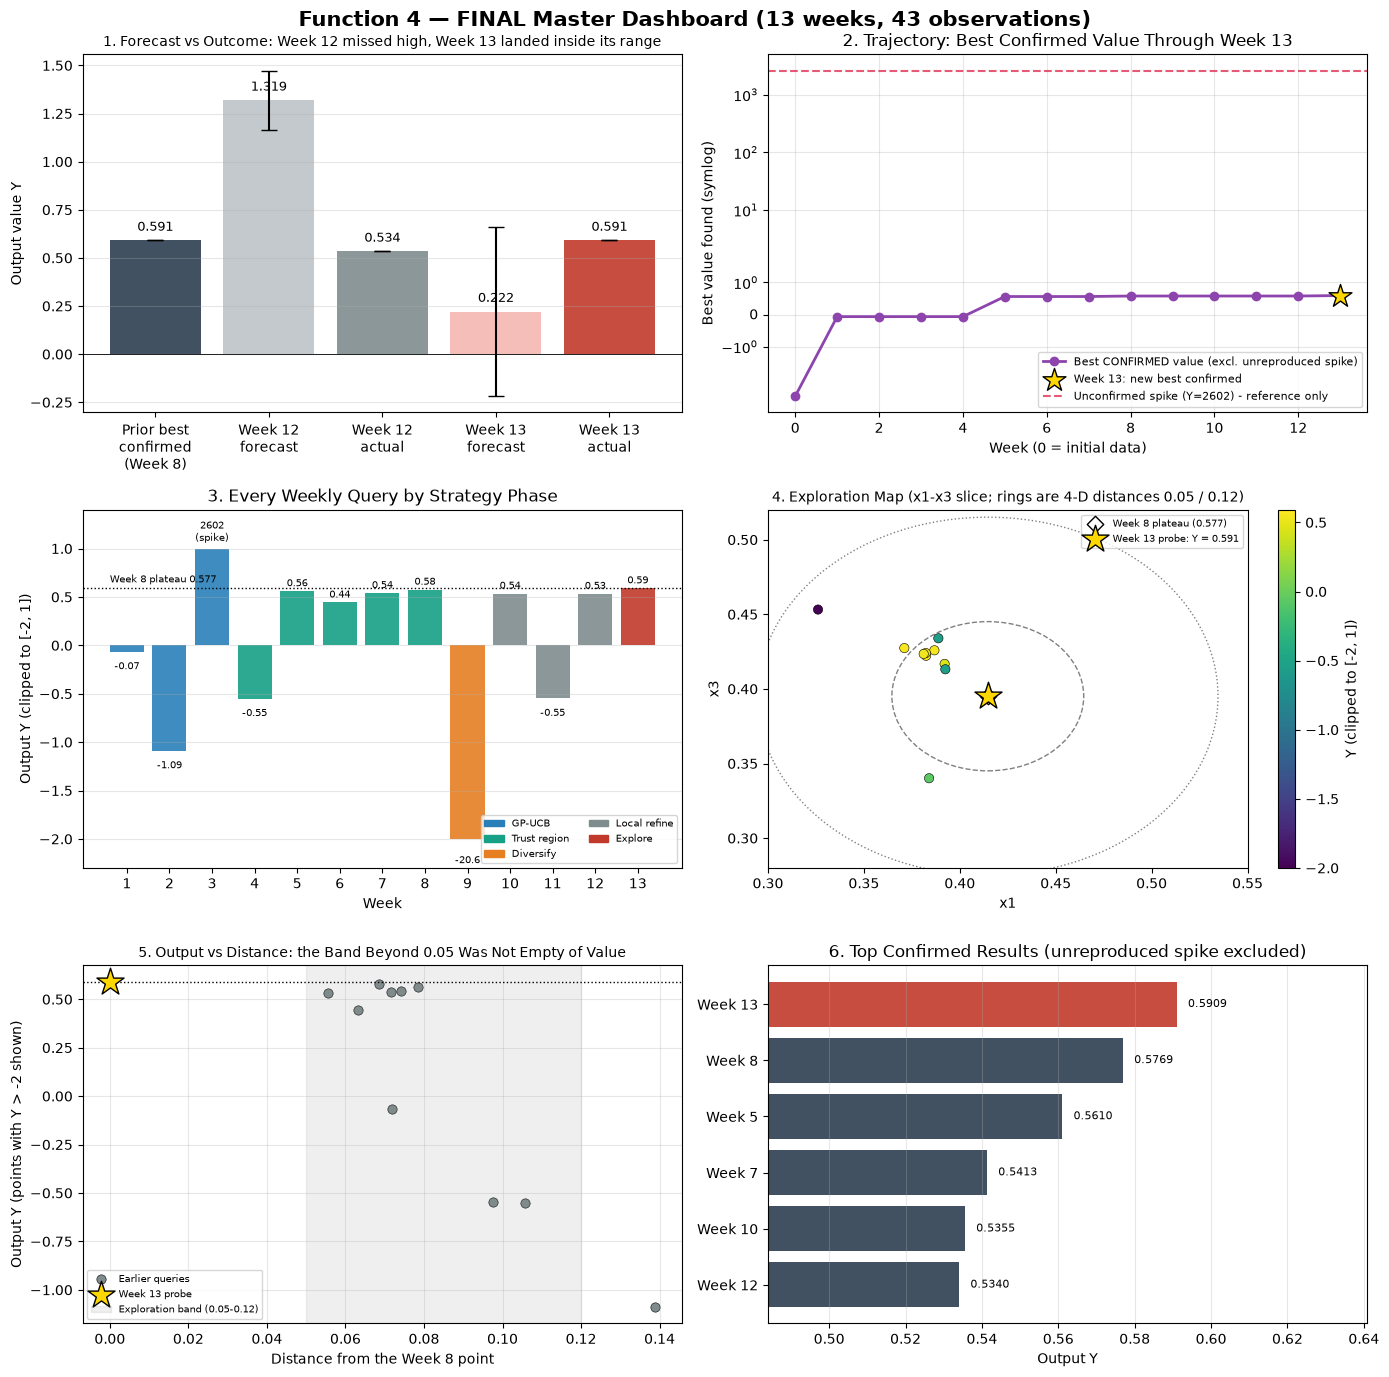

Panel 3 shows the one large miss (Week 9, diversification), the plateau queries of Weeks 5-12, and Week 13 as the best confirmed result.
Panel 5 shows the probe lies 0.0685 from the Week 8 point (4-D distance), beyond the 0.05 band edge, and beat every query inside it.


In [225]:
# Final dashboard (3x2): rebuilt around the whole 13-week campaign and the Week 13 result.
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
fig.suptitle("Function 4 — FINAL Master Dashboard (13 weeks, 43 observations)", fontsize=15, fontweight='bold')

# --- Panel 1: forecast vs outcome for the last two queries ---
ax1 = axes[0, 0]
labels_p1 = ['Prior best\nconfirmed\n(Week 8)', 'Week 12\nforecast', 'Week 12\nactual', 'Week 13\nforecast', 'Week 13\nactual']
# Week 12 forecast as recorded before that query (1.319 +/- 0.154); week12_result is recomputed on data that already holds the Week 12 point
W12_FORECAST, W12_SIGMA = 1.319, 0.154
values_p1 = [Y_best_confirmed, W12_FORECAST, Y_w12_new_point[0], explore_result['mu'], Y_w13_new_point[0]]
errors_p1 = [0, W12_SIGMA, 0, explore_result['sigma'], 0]
bars1 = ax1.bar(labels_p1, values_p1, yerr=errors_p1, capsize=6, alpha=0.9,
                color=['#2c3e50', '#bdc3c7', '#7f8c8d', '#f5b7b1', '#c0392b'])
for b_, v_ in zip(bars1, values_p1):
    ax1.text(b_.get_x() + b_.get_width() / 2, max(v_, 0) + 0.05, f'{v_:.3f}', ha='center', fontsize=9)
ax1.axhline(0, color='black', linewidth=0.6)
ax1.set_ylabel('Output value Y')
ax1.set_title('1. Forecast vs Outcome: Week 12 missed high, Week 13 landed inside its range')
ax1.title.set_fontsize(10)
ax1.grid(True, alpha=0.3, axis='y')

# --- Panel 2: weekly trajectory of the best CONFIRMED value, now through Week 13 ---
ax2 = axes[0, 1]
vals_true_final = [-4.025542281908162, -0.06634074624810848, -1.0896527174598272,
                   None, -0.5498551985786473, 0.5609901334222198, 0.4439603735656701,
                   0.5412633657393404, 0.5768690397535008, -20.576083860513034,
                   0.5355018178716588, -0.5478144020505584, 0.5339794849360797,
                   float(Y_w13_new_point[0])]
running_final = [vals_true_final[0]]
cur_max = vals_true_final[0]
for v in vals_true_final[1:]:
    if v is not None:
        cur_max = max(cur_max, v)
    running_final.append(cur_max)
ax2.plot(range(len(running_final)), running_final, 'o-', color='#8e44ad', linewidth=2, markersize=6,
         label='Best CONFIRMED value (excl. unreproduced spike)')
ax2.scatter([13], [running_final[-1]], marker='*', s=300, c='gold', edgecolors='black', zorder=5, label='Week 13: new best confirmed')
ax2.axhline(Y.max(), color='crimson', linestyle='--', alpha=0.7, label=f'Unconfirmed spike (Y={Y.max():.0f}) - reference only')
ax2.set_yscale('symlog')
ax2.set_xlabel('Week (0 = initial data)')
ax2.set_ylabel('Best value found (symlog)')
ax2.set_title('2. Trajectory: Best Confirmed Value Through Week 13')
ax2.legend(fontsize=8, loc='lower right')
ax2.grid(True, alpha=0.3)

# --- Panel 3: result of every weekly query, coloured by strategy phase ---
ax3 = axes[1, 0]
weekly = [v for v in vals_true_final[1:]]                       # Weeks 1..13 (Week 3 = None -> spike)
weekly = [Y.max() if v is None else v for v in weekly]
phase_of = {1: 'GP-UCB', 2: 'GP-UCB', 3: 'GP-UCB', 4: 'Trust region', 5: 'Trust region', 6: 'Trust region',
            7: 'Trust region', 8: 'Trust region', 9: 'Diversify', 10: 'Local refine', 11: 'Local refine',
            12: 'Local refine', 13: 'Explore'}
phase_col = {'GP-UCB': '#2980b9', 'Trust region': '#16a085', 'Diversify': '#e67e22', 'Local refine': '#7f8c8d', 'Explore': '#c0392b'}
for w_, v_ in zip(range(1, 14), weekly):
    shown = float(np.clip(v_, -2, 1))
    ax3.bar(w_, shown, color=phase_col[phase_of[w_]], alpha=0.9)
    if v_ != shown:
        ax3.text(w_, shown + (0.08 if shown > 0 else -0.25), f'{v_:.1f}' if abs(v_) < 100 else f'{v_:.0f}\n(spike)',
                 ha='center', fontsize=7)
    else:
        ax3.text(w_, shown + (0.05 if shown >= 0 else -0.18), f'{v_:.2f}', ha='center', fontsize=7)
ax3.axhline(Y_best_confirmed, color='black', linestyle=':', linewidth=1)
ax3.text(0.6, Y_best_confirmed + 0.06, 'Week 8 plateau 0.577', fontsize=7)
ax3.set_xticks(range(1, 14)); ax3.set_ylim(-2.3, 1.4)
ax3.set_xlabel('Week'); ax3.set_ylabel('Output Y (clipped to [-2, 1])')
ax3.set_title('3. Every Weekly Query by Strategy Phase')
handles = [plt.Rectangle((0, 0), 1, 1, color=c_) for c_ in phase_col.values()]
ax3.legend(handles, phase_col.keys(), fontsize=7, loc='lower right', ncol=2)
ax3.grid(True, alpha=0.3, axis='y')

# --- Panel 4: exploration map (x1 vs x3) with the observed Week 13 result ---
ax4 = axes[1, 1]
keep_ = Y < 100
sc = ax4.scatter(X[keep_, 0], X[keep_, 2], c=np.clip(Y[keep_], -2, 1), cmap='viridis', s=45, edgecolors='black', linewidths=0.4)
plt.colorbar(sc, ax=ax4, label='Y (clipped to [-2, 1])')
for r_, ls_ in ((0.05, '--'), (0.12, ':')):
    ax4.add_patch(plt.Circle((X_best_confirmed[0], X_best_confirmed[2]), r_, fill=False, color='gray', linestyle=ls_))
ax4.scatter([X_best_confirmed[0]], [X_best_confirmed[2]], marker='D', s=70, c='white', edgecolors='black', zorder=4, label='Week 8 plateau (0.577)')
ax4.scatter([X_w13_new_point[0]], [X_w13_new_point[2]], marker='*', s=420, c='gold', edgecolors='black', zorder=5,
            label=f'Week 13 probe: Y = {Y_w13_new_point[0]:.3f}')
ax4.set_xlim(0.30, 0.55); ax4.set_ylim(0.28, 0.52)
ax4.set_xlabel('x1'); ax4.set_ylabel('x3')
ax4.set_title('4. Exploration Map (x1-x3 slice; rings are 4-D distances 0.05 / 0.12)')
ax4.title.set_fontsize(10)
ax4.legend(fontsize=7, loc='upper right')

# --- Panel 5: output against distance from the Week 8 point (spike excluded) ---
ax5 = axes[2, 0]
dist_all = np.linalg.norm(X - X_best_confirmed, axis=1)
near_ = (Y < 100) & (dist_all < 0.15) & (Y > -2)
ax5.scatter(dist_all[near_], Y[near_], c='#7f8c8d', s=45, edgecolors='black', linewidths=0.4, label='Earlier queries')
ax5.scatter([dist_all[idx_w13]], [Y[idx_w13]], marker='*', s=420, c='gold', edgecolors='black', zorder=5, label='Week 13 probe')
ax5.axhline(Y_best_confirmed, color='black', linestyle=':', linewidth=1)
ax5.axvspan(0.05, 0.12, color='gray', alpha=0.12, label='Exploration band (0.05-0.12)')
ax5.set_xlabel('Distance from the Week 8 point'); ax5.set_ylabel('Output Y (points with Y > -2 shown)')
ax5.set_title('5. Output vs Distance: the Band Beyond 0.05 Was Not Empty of Value')
ax5.title.set_fontsize(10)
ax5.legend(fontsize=7, loc='lower left')
ax5.grid(True, alpha=0.3)

# --- Panel 6: top confirmed results (spike excluded) ---
ax6 = axes[2, 1]
order6 = [j for j in np.argsort(-Y) if Y[j] < 100][:6]
labs6 = [(f'Week {j - 29}' if j >= 30 else 'Initial') for j in order6]
vals6 = [Y[j] for j in order6]
cols6 = ['#c0392b' if j == idx_w13 else '#2c3e50' for j in order6]
ax6.barh(range(len(order6))[::-1], vals6, color=cols6, alpha=0.9)
ax6.set_yticks(range(len(order6))[::-1]); ax6.set_yticklabels(labs6)
for pos_, v_ in zip(range(len(order6))[::-1], vals6):
    ax6.text(v_ + 0.003, pos_, f'{v_:.4f}', va='center', fontsize=8)
ax6.set_xlim(min(vals6) - 0.05, max(vals6) + 0.05)
ax6.set_xlabel('Output Y')
ax6.set_title('6. Top Confirmed Results (unreproduced spike excluded)')
ax6.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('final_master_dashboard.png', dpi=120)
plt.show()

print("Panel 3 shows the one large miss (Week 9, diversification), the plateau queries of Weeks 5-12, and Week 13 as the best confirmed result.")
print("Panel 5 shows the probe lies 0.0685 from the Week 8 point (4-D distance), beyond the 0.05 band edge, and beat every query inside it.")

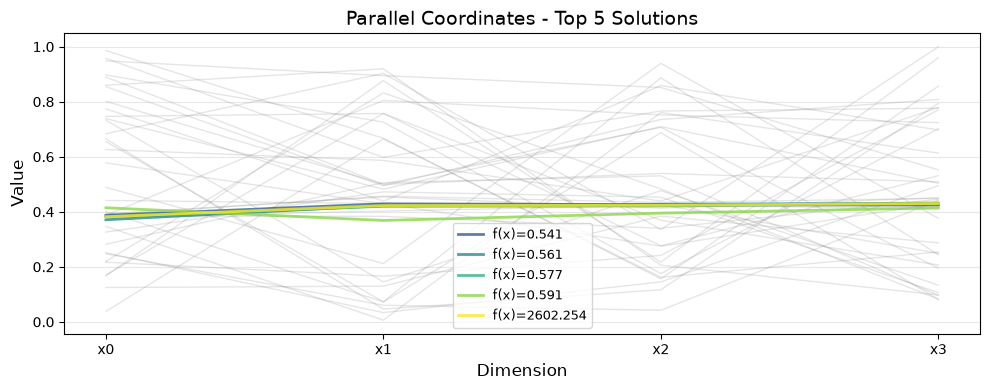

In [226]:
# Parallel coordinates: how does the new best point compare to other top solutions?
plot_parallel_coordinates(X, Y, n_best = 5)
plt.show()

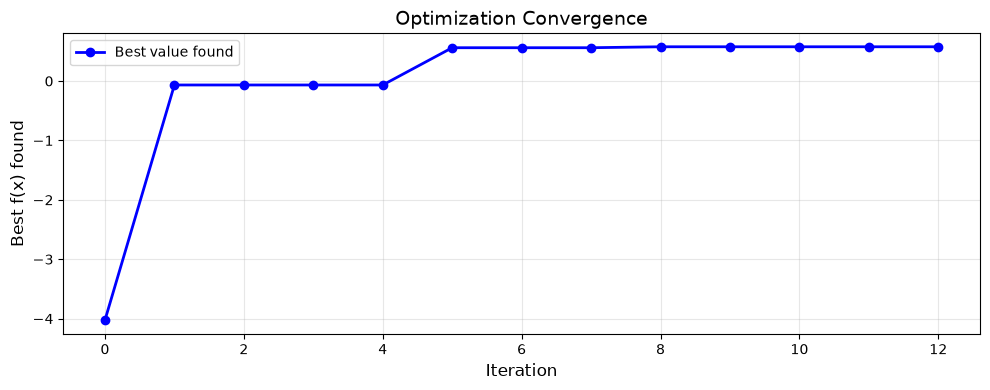

Convergence trace (confirmed best value at each stage): [-4.025542281908162, -0.06634074624810848, -0.06634074624810848, -0.06634074624810848, -0.06634074624810848, 0.5609901334222198, 0.5609901334222198, 0.5609901334222198, 0.5768690397535008, 0.5768690397535008, 0.5768690397535008, 0.5768690397535008, 0.5768690397535008]


In [229]:
# Convergence so far (final update)
best_values_w13 = running_w13  # from the running-max calculation in the dashboard cell above
plot_convergence(range(len(best_values_w13)), best_values_w13)
plt.show()
print("Convergence trace (confirmed best value at each stage):", best_values_w13)